# Lab02 chuẩn — ResNet18 và DenseNet121 trên CIFAR10

Hai kiến trúc, bốn điều kiện: ResNet head/fine-tune và DenseNet head/fine-tune. Khởi tạo pretrained ImageNet; head cache feature, train 10 epoch. Mỗi model có 3 trial Optuna tìm LR chung, tối đa 10 epoch/trial. AdamW, weight decay 1e-4, cosine. Không augmentation/dropout/pruning. Checkpoint/objective/early stopping cùng theo validation loss; fine-tune patience 3, min_delta 0.001, từ epoch 4. Đây là notebook chuẩn mới; không dùng kết quả 5+5 trial LR chung/riêng cũ.

Notebook dùng chung src.standard_suite với local. Từng stage gọi backend riêng, vẽ loss/accuracy/LR ngay mỗi epoch và bảng search sau mỗi trial. Test chỉ sau khi cả hai model đã khóa lựa chọn. Không cam kết dưới 5 giờ trước khi đo.

## Pipeline Execution Roadmap

| Bước | Phase | Nội dung | Module | Artifact |
|---|---|---|---|---|
| 1 | Setup | Source, GPU, dependencies, seed | bootstrap; experiment.seed_all | setup/environment.json |
| 2 | Dữ liệu/EDA | Official CIFAR10, checksum, split, bảng và ảnh | eda.build, read_raw, locked_split | outputs/eda/* |
| 3 | Preprocess | RGB 224x224 theo weights, không augmentation | data.image_transform | actual_model_preprocessing.png, preprocessing.json |
| 4 | Architecture | Hai model; frozen/trainable | models.configure_trainable | architecture.txt, parameter_scope.csv |
| 5 | ResNet head | Cache train/val feature một lần; train classifier | Suite.head, cached_features | feature cache, history, head_selected/best.pt |
| 6 | ResNet tuning | 3 LR trial, mở layer4+fc | Suite.search; experiment.fit | study.sqlite3, trials.csv, trial_XX/*, selection.json |
| 7 | DenseNet head | Cache feature và head mới | Suite.head | như ResNet head |
| 8 | DenseNet tuning | 3 LR trial, block4+norm5+classifier | Suite.search | study/trial artifacts |
| 9 | Test sau khóa | Bốn điều kiện, confusion/ROC/PR/predictions | Suite.evaluate, reporting.export_evaluation | evaluation/head và evaluation/finetune |
| 10 | Save/load | Model độc lập, full test, probability tolerance | Suite.evaluate | loaded/, roundtrip.json |
| 11 | Tổng hợp/bàn giao | So sánh bốn điều kiện, manifest và ZIP | notebook; Suite.manifest | comparison.csv/png, registry, ZIP |

Các checkpoint trước hoàn tất được giữ riêng; đọc registry mới không tự chạy lại các stage đã hoàn tất. Trial bị ngắt không được tự tiếp tục như thể đã resume đúng RNG/optimizer.

## 1. Setup Kaggle

Upload ZIP source mới nhất làm Input, bật GPU và Internet. Source/Input chỉ đọc, output dưới /kaggle/working. Local có thể dùng backend bằng Suite(root=thư_mục_lab, device='cpu' hoặc 'cuda'); bootstrap bên dưới dành Kaggle.

In [1]:
from pathlib import Path
import sys, subprocess, zipfile, shutil, json, os
import torch
assert torch.cuda.is_available(), 'Bật GPU trong cài đặt notebook trước khi chạy.'
print(torch.__version__, torch.cuda.get_device_name(0))
WORK = Path('/kaggle/working/lab02_standard')
# Có nhiều bộ source thì chọn đường dẫn ở đây; mặc định tự tìm.
SOURCE_ROOT = None
SOURCE_ZIP = None
required = ('src/standard_suite.py', 'config/standard.json', 'tests/test_optuna_dense.py')
if (WORK/'outputs/runs').exists():
    assert all((WORK/p).is_file() for p in required), 'Run đã tồn tại nhưng source thiếu. Không ghi đè source của run.'
    print('Giữ nguyên source và run đã có. Không chạy lại cell TRAINING nếu chỉ xem kết quả.')
else:
    if SOURCE_ROOT is None and SOURCE_ZIP is None:
        roots = sorted({p.parent.parent for p in Path('/kaggle/input').rglob('optuna_dense.py')
                        if p.parent.name == 'src' and all((p.parent.parent/f).is_file() for f in required)})
        archives = sorted(Path('/kaggle/input').rglob('lab02_standard_source.zip'))
        if len(roots) == 1:
            SOURCE_ROOT = roots[0]
        elif not roots and len(archives) == 1:
            SOURCE_ZIP = archives[0]
        else:
            print('Source folders:', roots)
            print('Source archives:', archives)
            raise RuntimeError('Không xác định được một bộ source mới. Mở scr-lab02 trong Input, kiểm tra src/standard_suite.py và config/standard.json; đặt SOURCE_ROOT hoặc SOURCE_ZIP nếu có nhiều bản.')
    if SOURCE_ROOT is not None:
        SOURCE_ROOT = Path(SOURCE_ROOT)
        assert all((SOURCE_ROOT/p).is_file() for p in required), 'Dataset thiếu source Optuna mới; upload ZIP mới.'
        WORK.mkdir(parents=True, exist_ok=True)
        for name in ('src','config','tests'):
            shutil.copytree(SOURCE_ROOT/name, WORK/name, dirs_exist_ok=True)
    else:
        with zipfile.ZipFile(SOURCE_ZIP) as archive:
            names = archive.namelist()
            assert all(p in names for p in required), 'ZIP thiếu source/config/test mới.'
            for member in archive.infolist():
                assert (WORK/member.filename).resolve().is_relative_to(WORK.resolve()), 'Đường dẫn ZIP không hợp lệ'
            WORK.mkdir(parents=True, exist_ok=True)
            archive.extractall(WORK)
assert all((WORK/p).is_file() for p in required)
sys.path.insert(0, str(WORK))
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'optuna>=4,<5', 'tensorboard', 'scikit-learn', 'pandas', 'matplotlib', 'pytest'], check=True)
print('Source ready:', WORK)


2.11.0+cu128 Tesla T4
Source ready: /kaggle/working/lab02_standard


In [2]:
import platform, importlib.metadata as metadata
import numpy as np
import pandas as pd
from IPython.display import display, Image, FileLink, Markdown
from src.delivery import write_json, file_hash
from src.experiment import seed_all
seed_all(42)
SETUP = WORK/'outputs/setup'
SETUP.mkdir(parents=True, exist_ok=True)
environment = {'python':platform.python_version(),'device':torch.cuda.get_device_name(0),
    'libraries':{name:metadata.version(name) for name in ('torch','torchvision','numpy','pandas','optuna','tensorboard')}}
write_json(SETUP/'environment.json', environment)
display(pd.Series(environment['libraries'], name='version').to_frame())


,version
torch,2.11.0+cu128
torchvision,0.26.0+cu128
numpy,2.1.3
pandas,2.3.3
optuna,4.9.0
tensorboard,2.20.0


## 2. CIFAR10 và cấu hình

50.000 ảnh official train chia stratified 45.000/5.000, test official 10.000. Checksum xác minh trước khi dùng. Không dùng test để chọn LR.

In [3]:
raw = list(Path('/kaggle/input').rglob('cifar-10-batches-py'))
if len(raw) == 1:
    DATA = raw[0].parent
else:
    DATA = WORK/'data'
    from torchvision.datasets import CIFAR10
    CIFAR10(str(DATA), train=True, download=True)
    CIFAR10(str(DATA), train=False, download=True)
os.environ['LAB02_DATA'] = str(DATA)
cfg = json.loads((WORK/'config/standard.json').read_text())
CONFIG = WORK/'config/kaggle_optuna.json'
CONFIG.write_text(json.dumps(cfg, indent=2))
from src.eda import read_raw
pool, labels, test_images, test_labels = read_raw(DATA)
assert len(labels) == 50000 and len(test_labels) == 10000
print('Data:', DATA)
print('Budget:', len(cfg['models'])*cfg['trials_per_model'], 'trials, max', cfg['finetune_epochs'], 'epochs/trial')
del pool, test_images


100%|██████████| 170M/170M [36:42<00:00, 77.4kB/s]


Data: /kaggle/working/lab02_standard/data
Budget: 6 trials, max 10 epochs/trial


## 3. EDA và kiểm chứng preprocessing

Giữ EDA đầy đủ của Lab02; feature thủ công chỉ mô tả dữ liệu, không nối vào DenseNet/ResNet. EDA preview cũ có resize riêng; preview actual_model_preprocessing bên dưới mới là transform 224x224 thực dùng.

In [4]:
from src import eda
EDA = eda.build(WORK, data_dir=DATA)
for name in ('structural_overview.csv','integrity_report.csv','class_distribution.csv','pixel_statistics.csv'):
    print(name)
    display(pd.read_csv(EDA/name))
duplicates = pd.read_csv(EDA/'duplicate_images.csv')
print('Exact duplicate records:', len(duplicates))
with np.load(EDA/'split_indices.npz', allow_pickle=False) as split:
    assert len(np.intersect1d(split['train'], split['val'])) == 0
    display(pd.DataFrame({'split':split.files,'samples':[len(split[k]) for k in split.files]}))


structural_overview.csv


,split,samples,shape,dtype,pixel_min,pixel_max,memory_mib
0,train,45000,32 x 32 x 3,uint8,0,255,131.835938
1,val,5000,32 x 32 x 3,uint8,0,255,14.648438
2,test,10000,32 x 32 x 3,uint8,0,255,29.296875


integrity_report.csv


,split,check,count
0,train,invalid_labels,0
1,train,nonfinite_pixels,0
2,train,constant_images,0
3,val,invalid_labels,0
4,val,nonfinite_pixels,0
5,val,constant_images,0
6,test,invalid_labels,0
7,test,nonfinite_pixels,0
8,test,constant_images,0


class_distribution.csv


,Unnamed: 0,train,val,test
0,airplane,4500,500,1000
1,automobile,4500,500,1000
2,bird,4500,500,1000
3,cat,4500,500,1000
4,deer,4500,500,1000
5,dog,4500,500,1000
6,frog,4500,500,1000
7,horse,4500,500,1000
8,ship,4500,500,1000
9,truck,4500,500,1000


pixel_statistics.csv


,channel,mean,std,zero_fraction
0,R,0.491137,0.246869,0.002398
1,G,0.482111,0.243430,0.002314
2,B,0.446449,0.261603,0.002499


Exact duplicate records: 0


,split,samples
0,train,45000
1,val,5000
2,test,10000


sample_images.png


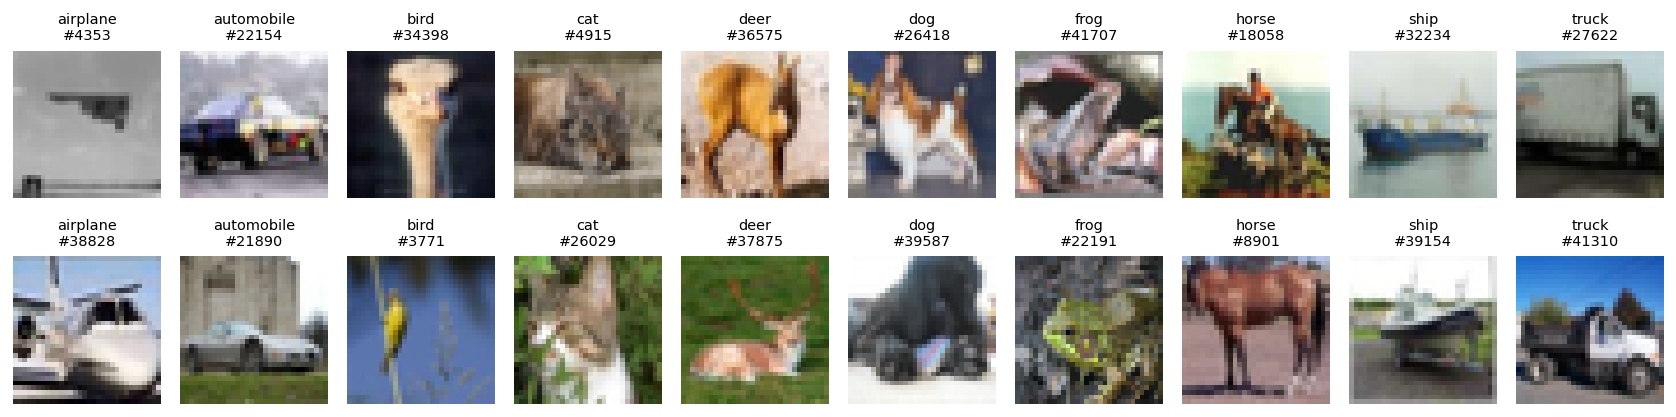

class_distribution.png


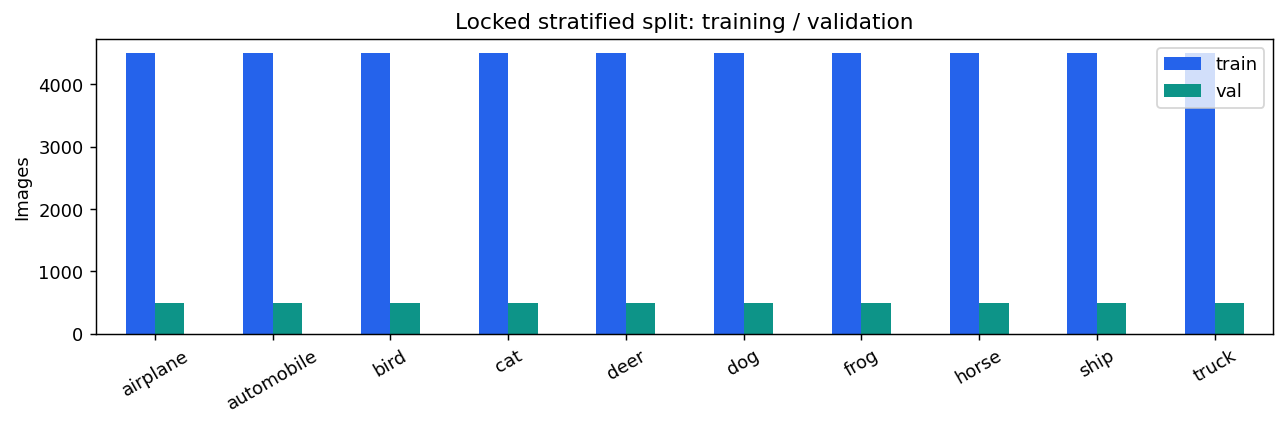

class_mean_images.png


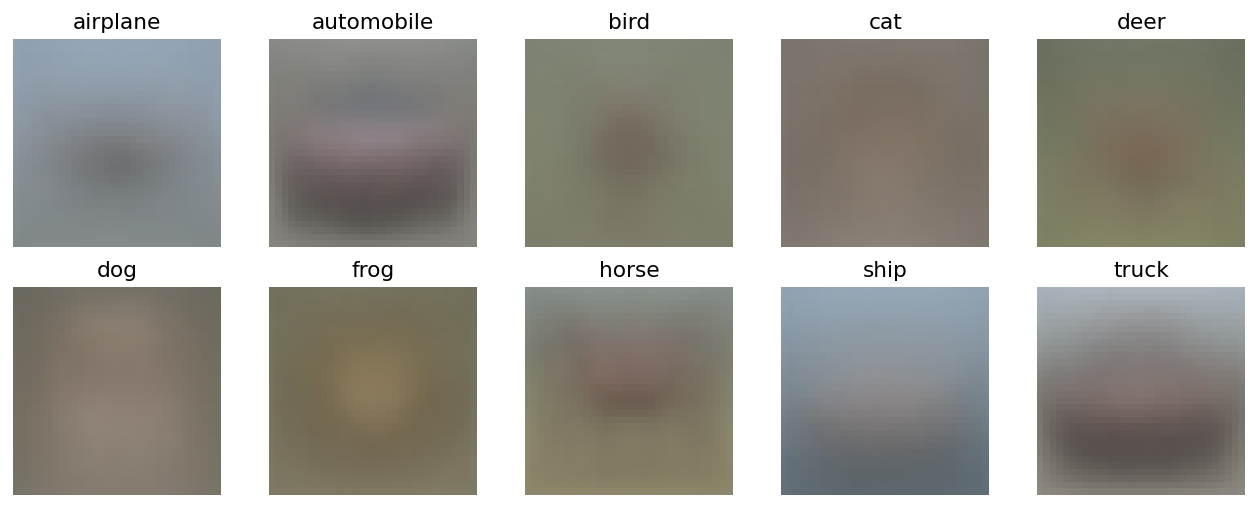

pixel_statistics.png


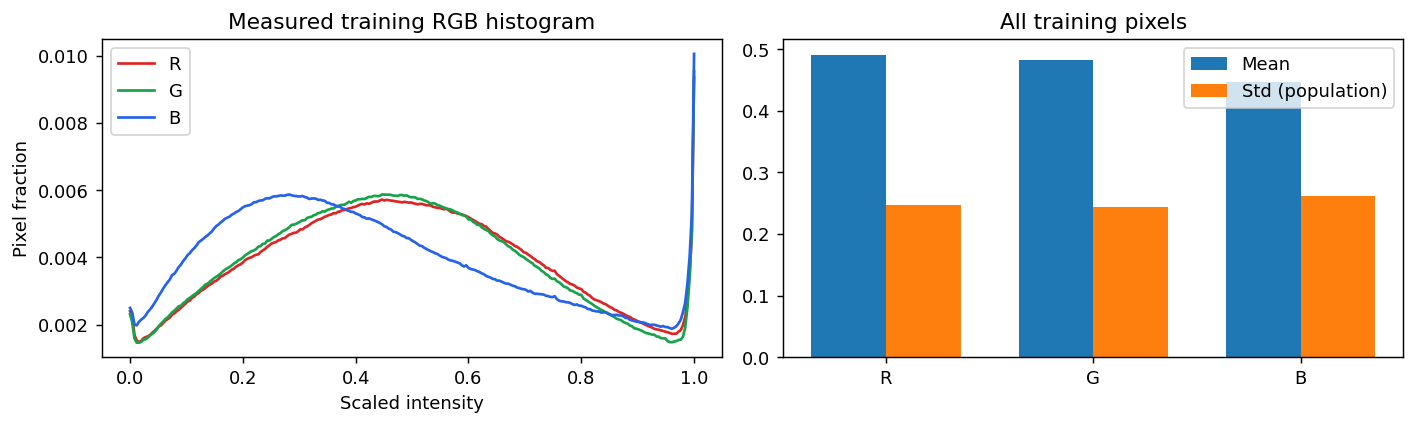

spatial_statistics.png


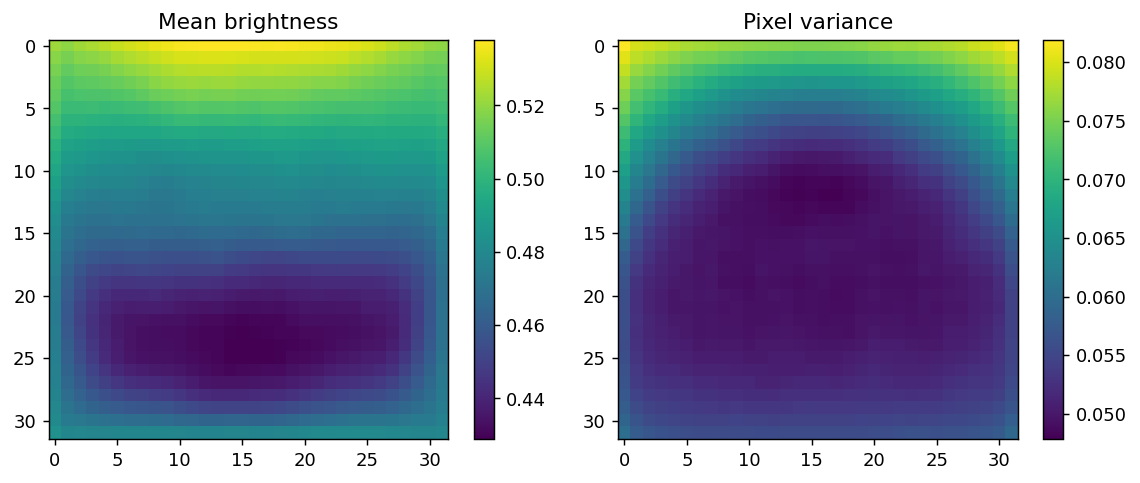

class_similarity.png


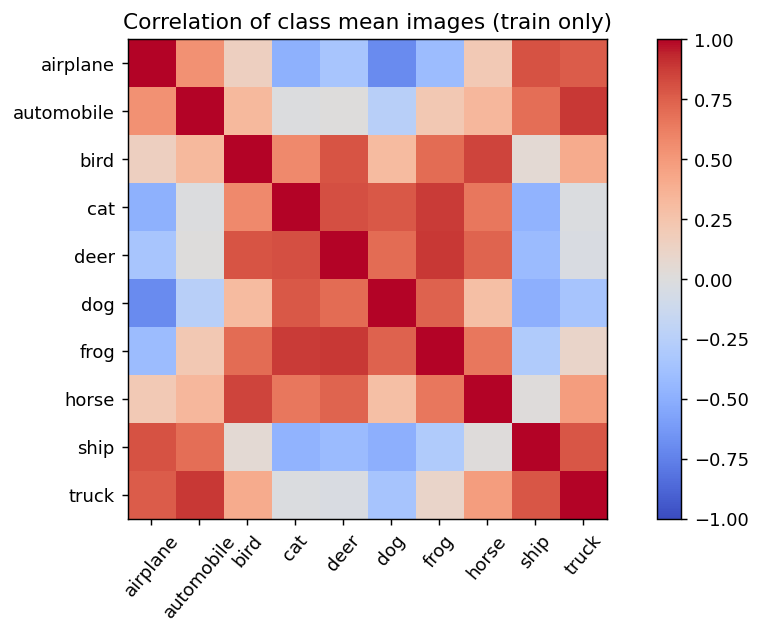

handcrafted_distributions.png


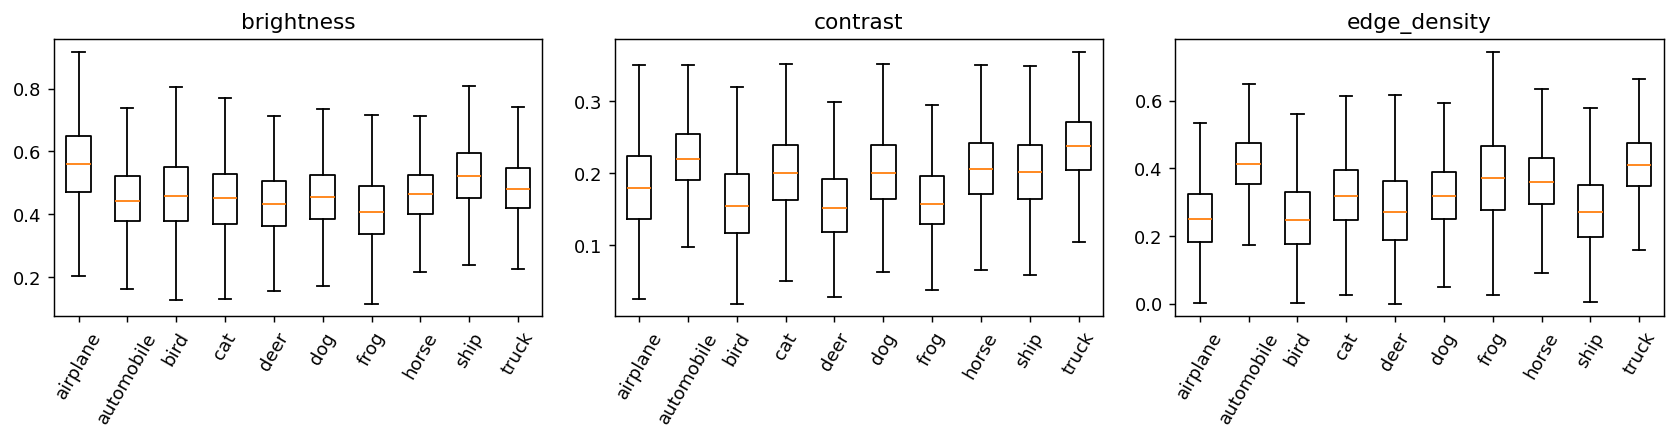

feature_correlation.png


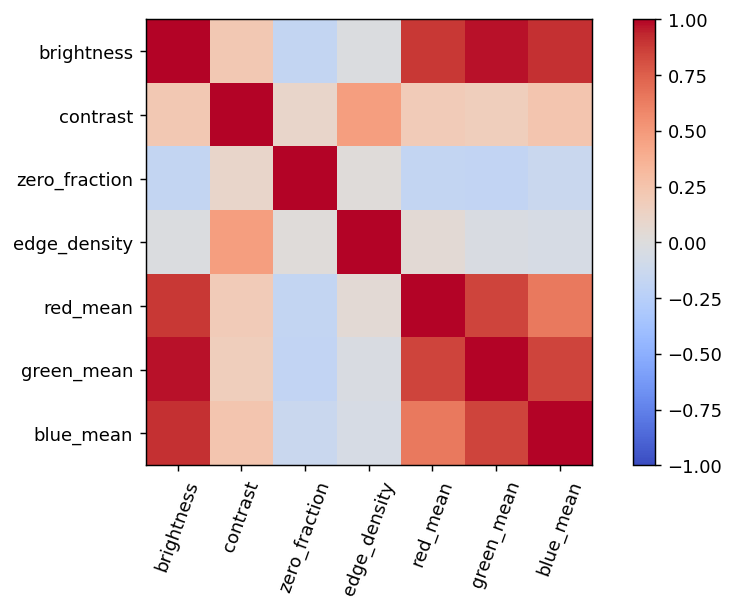

In [5]:
for name in ('sample_images.png','class_distribution.png','class_mean_images.png','pixel_statistics.png','spatial_statistics.png','class_similarity.png','handcrafted_distributions.png','feature_correlation.png'):
    print(name)
    display(Image(filename=str(EDA/name)))


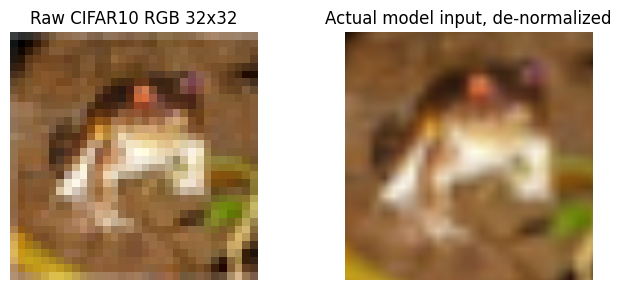

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [6]:
from src.data import image_transform
from torchvision.datasets import CIFAR10
import matplotlib.pyplot as plt
raw_dataset = CIFAR10(str(DATA), train=True, download=False)
raw_image, label = raw_dataset[0]
transform = image_transform('densenet121', cfg['image_size'])
tensor = transform(raw_image)
assert tensor.shape == (3,224,224) and torch.isfinite(tensor).all()
from src.models import SPECS
contract = SPECS['densenet121'][1].transforms()
recovered = (tensor*torch.tensor(contract.std)[:,None,None] + torch.tensor(contract.mean)[:,None,None]).clamp(0,1)
fig, axes = plt.subplots(1,2,figsize=(7,3))
axes[0].imshow(raw_image); axes[0].set_title('Raw CIFAR10 RGB 32x32')
axes[1].imshow(recovered.permute(1,2,0)); axes[1].set_title('Actual model input, de-normalized')
for ax in axes: ax.axis('off')
fig.tight_layout(); fig.savefig(SETUP/'actual_model_preprocessing.png',dpi=140); display(fig); plt.close(fig)
write_json(SETUP/'preprocessing.json',{'transform':str(transform),'shape':list(tensor.shape),
    'dtype':str(tensor.dtype),'normalization_mean':contract.mean,'normalization_std':contract.std,'augmentation':False})
print(transform)


## 4. Kiến trúc và ngân sách

Head-only chỉ train classifier. Fine-tune ResNet layer4+fc; DenseNet toàn bộ 16 dense layer block4+norm5+classifier. BatchNorm statistics giữ cố định. Tìm LR log [1e-6,1e-3], weight decay cố định; TPE 2 startup trial và 1 trial thích nghi mỗi model. Ba trial là khảo sát ngân sách nhỏ, không chứng minh tối ưu toàn cục.

,model,stage,total,trainable
0,resnet18,head,11181642,5130
1,resnet18,finetune,11181642,8398858
2,densenet121,head,6964106,10250
3,densenet121,finetune,6964106,2170378


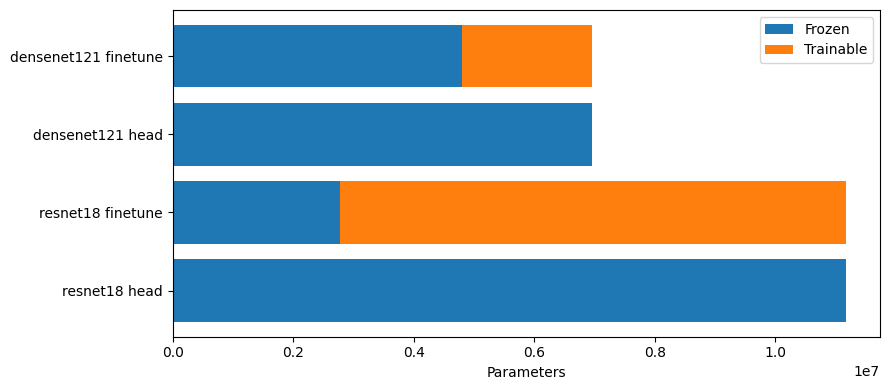

,configuration
models,"[resnet18, densenet121]"
seed,42
split_seed,42
threads,4
train_limit,0
val_limit,0
test_limit,0
image_size,224
batch_size,128
feature_batch_size,64


In [7]:
from src.models import build_model,configure_trainable,parameter_counts
scopes=[]
for name in cfg['models']:
    model=build_model(name,pretrained=False)
    (SETUP/f'{name}_architecture.txt').write_text(str(model))
    for stage in ('head','finetune'):
        configure_trainable(model,name,stage,'last_block')
        scopes.append({'model':name,'stage':stage,**parameter_counts(model)})
        pd.DataFrame([{'name':n,'parameters':p.numel(),'trainable':p.requires_grad} for n,p in model.named_parameters()]).to_csv(SETUP/f'{name}_{stage}_parameter_scope.csv',index=False)
    del model
scopes=pd.DataFrame(scopes);display(scopes)
fig,ax=plt.subplots(figsize=(9,4))
labels=scopes.model+' '+scopes.stage
ax.barh(labels,scopes.total-scopes.trainable,label='Frozen')
ax.barh(labels,scopes.trainable,left=scopes.total-scopes.trainable,label='Trainable')
ax.set_xlabel('Parameters');ax.legend();fig.tight_layout();fig.savefig(SETUP/'architecture_visual.png',dpi=130);display(fig);plt.close(fig)
display(pd.Series(cfg).to_frame('configuration'))


model,stage,total,trainable,frozen,unfrozen_pct,unfrozen_parts
densenet121,finetune,6964106,2170378,4793728,31.1652,denseblock4 + norm5 + classifier
densenet121,head,6964106,10250,6953856,0.1472,classifier
resnet18,finetune,11181642,8398858,2782784,75.1129,layer4 + fc
resnet18,head,11181642,5130,11176512,0.0459,classifier


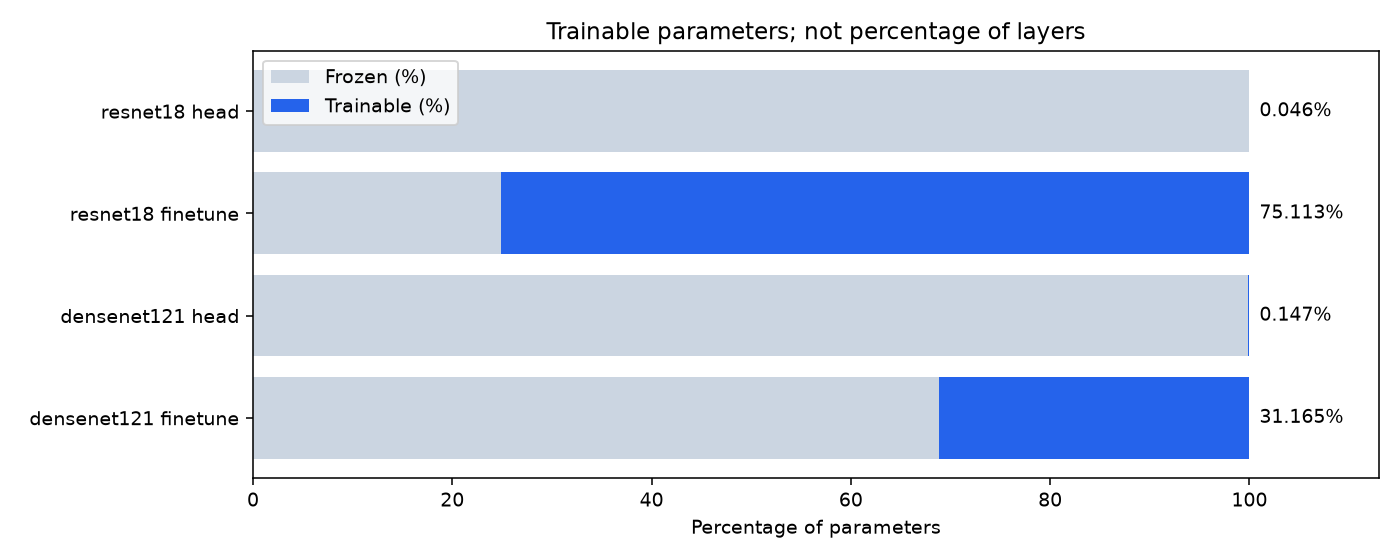

In [15]:
from pathlib import Path
import sys
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p/'config/standard.json').is_file()), None) or next(p/'labs/lab02' for p in candidates if (p/'labs/lab02/config/standard.json').is_file())
sys.path.insert(0, str(ROOT))
from src.utils.notebook_views import standard_parameter_summary
scope_table = standard_parameter_summary(ROOT)

## 5. Kiểm thử và tạo/reuse run

Test dùng dữ liệu nhỏ, không train benchmark. Registry tự tái dùng các stage hoàn tất; không resume trial bị ngắt. Có thể đặt EXISTING_RUN thành đường dẫn run được khôi phục cùng config. Không chạy lại phiên đang train song song.

In [8]:
subprocess.run([sys.executable,'-m','pytest','tests/test_standard_suite.py','tests/test_optuna_dense.py','-q'],cwd=WORK,check=True)
from src.standard_suite import Suite
REGISTRY=WORK/'outputs/selected_standard.json'
EXISTING_RUN=None
if EXISTING_RUN is None and REGISTRY.exists():
    EXISTING_RUN=WORK/json.loads(REGISTRY.read_text())['run']
suite=Suite(WORK,config_path=CONFIG,run_path=EXISTING_RUN,device='cuda',live=True)
RUN=suite.run
write_json(REGISTRY,{'run':str(RUN.relative_to(WORK))})
print('Active run:',RUN)


.....                                                                    [100%]
=============================== warnings summary ===============================
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:64
  /usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:64: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
    prop = Group((name + Suppress("=") + comma_separated(value)) | oneOf(_CONSTANTS))

../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
  /usr/local/l

## 6. ResNet18 head-only

Trích xuất feature train/val ở eval mode một lần rồi train head 10 epoch. Plot cập nhật từng epoch, lưu learning_curves.png và history.csv. Chi phí extraction được ghi riêng, không gọi là thời gian train head.

Stage: resnet18/head
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /kaggle/working/lab02_standard/data/pretrained/checkpoints/resnet18-f37072fd.pth


100%|##########| 44.7M/44.7M [00:00<00:00, 185MB/s]


resnet18 extract train: 64/45000
resnet18 extract train: 1664/45000
resnet18 extract train: 3264/45000
resnet18 extract train: 4864/45000
resnet18 extract train: 6464/45000
resnet18 extract train: 8064/45000
resnet18 extract train: 9664/45000
resnet18 extract train: 11264/45000
resnet18 extract train: 12864/45000
resnet18 extract train: 14464/45000
resnet18 extract train: 16064/45000
resnet18 extract train: 17664/45000
resnet18 extract train: 19264/45000
resnet18 extract train: 20864/45000
resnet18 extract train: 22464/45000
resnet18 extract train: 24064/45000
resnet18 extract train: 25664/45000
resnet18 extract train: 27264/45000
resnet18 extract train: 28864/45000
resnet18 extract train: 30464/45000
resnet18 extract train: 32064/45000
resnet18 extract train: 33664/45000
resnet18 extract train: 35264/45000
resnet18 extract train: 36864/45000
resnet18 extract train: 38464/45000
resnet18 extract train: 40064/45000
resnet18 extract train: 41664/45000
resnet18 extract train: 43264/45000
r

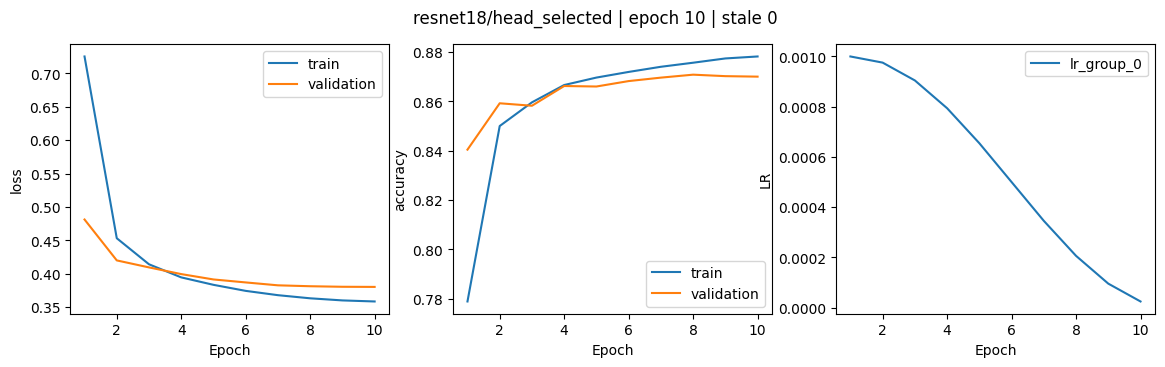

  train: 32128/45000
head_selected epoch 2/10: train=0.8500, val=0.8592
  train: 32128/45000
head_selected epoch 3/10: train=0.8596, val=0.8582
  train: 32128/45000
head_selected epoch 4/10: train=0.8666, val=0.8662
  train: 32128/45000
head_selected epoch 5/10: train=0.8696, val=0.8660
  train: 32128/45000
head_selected epoch 6/10: train=0.8719, val=0.8682
  train: 32128/45000
head_selected epoch 7/10: train=0.8740, val=0.8696
  train: 32128/45000
head_selected epoch 8/10: train=0.8756, val=0.8708
  train: 32128/45000
head_selected epoch 9/10: train=0.8774, val=0.8702
  train: 32128/45000
head_selected epoch 10/10: train=0.8782, val=0.8700
Head checkpoint locked: /kaggle/working/lab02_standard/outputs/runs/20261030T095916Z_standard_bb2ef6d8/resnet18/head_selected


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,epoch_seconds,train_pass_seconds,validation_seconds,train_images_per_second,lr_group_0
0,1,0.725307,0.778844,0.481143,0.8404,1.201010,1.130363,0.070618,39810.230822,0.001000
1,2,0.453100,0.849978,0.419893,0.8592,0.884777,0.823439,0.061105,54648.888729,0.000976
2,3,0.414064,0.859578,0.409412,0.8582,0.881642,0.823134,0.058329,54669.115887,0.000905
3,4,0.394460,0.866600,0.399392,0.8662,0.876480,0.818472,0.057839,54980.516505,0.000794
4,5,0.383315,0.869622,0.391353,0.8660,0.887702,0.829765,0.057704,54232.203749,0.000655
5,6,0.374267,0.871911,0.386906,0.8682,0.854621,0.796076,0.058358,56527.288040,0.000500
6,7,0.367812,0.874000,0.382569,0.8696,0.869862,0.812106,0.057382,55411.460038,0.000345
7,8,0.363124,0.875644,0.381205,0.8708,0.883568,0.826350,0.057051,54456.354379,0.000206
8,9,0.359971,0.877378,0.380394,0.8702,0.851490,0.794090,0.057152,56668.673187,0.000095
9,10,0.358387,0.878178,0.380198,0.8700,0.861988,0.804085,0.057738,55964.221084,0.000024


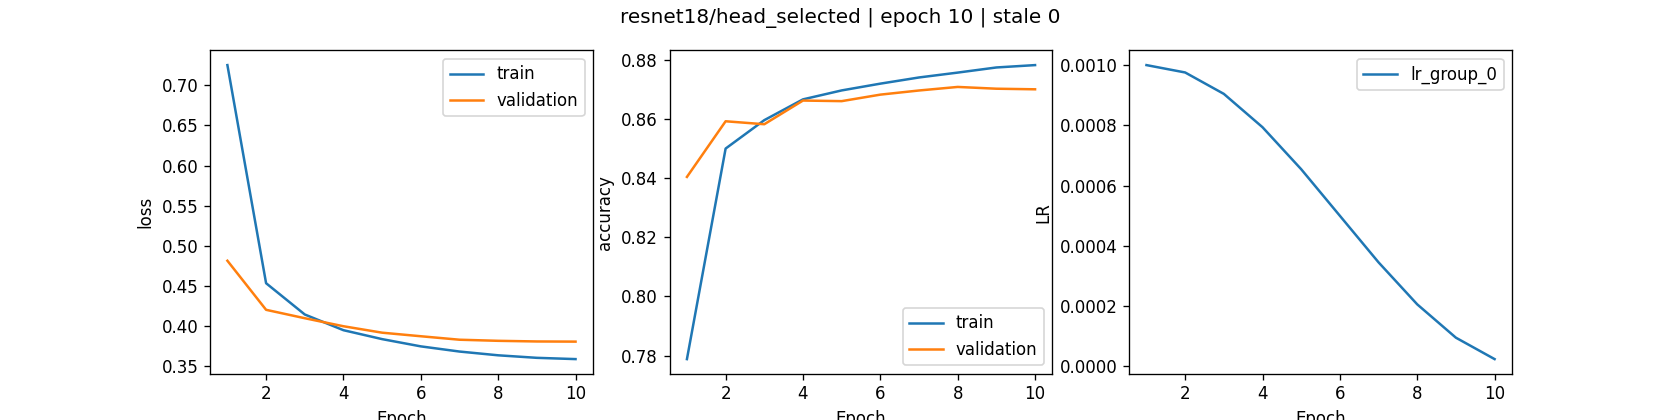

In [9]:
try:
    resnet_head=suite.head('resnet18')
finally:
    shutil.make_archive('/kaggle/working/lab02_standard_outputs','zip',WORK,'outputs')
display(pd.read_csv(resnet_head/'history.csv'))
display(Image(filename=str(resnet_head/'learning_curves.png')))


## 7. ResNet18 fine-tune và Optuna

3 trial, LR chung cho layer4+fc, giữ split và cùng checkpoint head cho mọi trial. Sau mỗi epoch hiện loss/accuracy/LR; bảng Optuna cập nhật sau mỗi trial. Chưa đọc test.

Stage: resnet18/search


[I 2026-10-30 10:01:48,104] A new study created in RDB with name: resnet18


  train: 32128/45000
trial_00 epoch 1/10: train=0.8886, val=0.8950


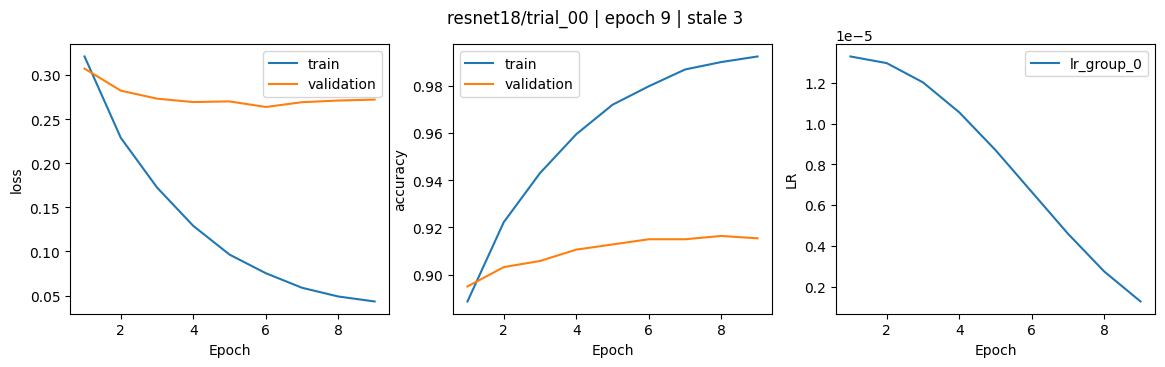

  train: 32128/45000
trial_00 epoch 2/10: train=0.9222, val=0.9032
  train: 32128/45000
trial_00 epoch 3/10: train=0.9430, val=0.9058
  train: 32128/45000
trial_00 epoch 4/10: train=0.9595, val=0.9106
  train: 32128/45000
trial_00 epoch 5/10: train=0.9720, val=0.9128
  train: 32128/45000
trial_00 epoch 6/10: train=0.9798, val=0.9150
  train: 32128/45000
trial_00 epoch 7/10: train=0.9869, val=0.9150
  train: 32128/45000
trial_00 epoch 8/10: train=0.9901, val=0.9164
  train: 32128/45000
trial_00 epoch 9/10: train=0.9924, val=0.9154


[I 2026-10-30 10:24:09,019] Trial 0 finished with value: 0.263887745398283 and parameters: {'lr': 1.329291894316217e-05}. Best is trial 0 with value: 0.263887745398283.


,number,value,datetime_start,datetime_complete,duration,params_lr,user_attrs_best_epoch,user_attrs_epochs_completed,state
0,0,0.263888,2026-10-30 10:01:48.113022,2026-10-30 10:24:09.002219,0 days 00:22:20.889197,0.000013,6,9,COMPLETE


  train: 32128/45000
trial_01 epoch 1/10: train=0.1041, val=0.1000


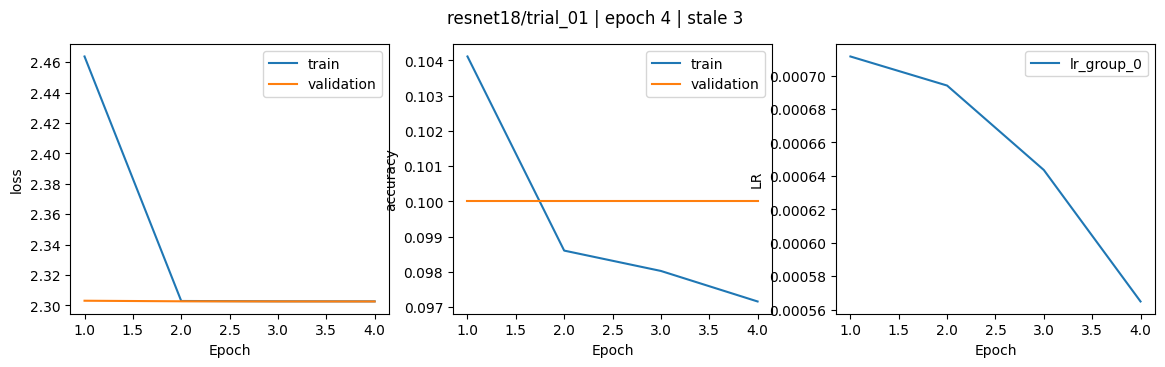

  train: 32128/45000
trial_01 epoch 2/10: train=0.0986, val=0.1000
  train: 32128/45000
trial_01 epoch 3/10: train=0.0980, val=0.1000
  train: 32128/45000
trial_01 epoch 4/10: train=0.0972, val=0.1000


[I 2026-10-30 10:34:05,390] Trial 1 finished with value: 2.303079536437988 and parameters: {'lr': 0.0007114476009343421}. Best is trial 0 with value: 0.263887745398283.


,number,value,datetime_start,datetime_complete,duration,params_lr,user_attrs_best_epoch,user_attrs_epochs_completed,state
0,0,0.263888,2026-10-30 10:01:48.113022,2026-10-30 10:24:09.002219,0 days 00:22:20.889197,0.000013,6,9,COMPLETE
1,1,2.303080,2026-10-30 10:24:09.044375,2026-10-30 10:34:05.380872,0 days 00:09:56.336497,0.000711,1,4,COMPLETE


  train: 32128/45000
trial_02 epoch 1/10: train=0.8819, val=0.8774


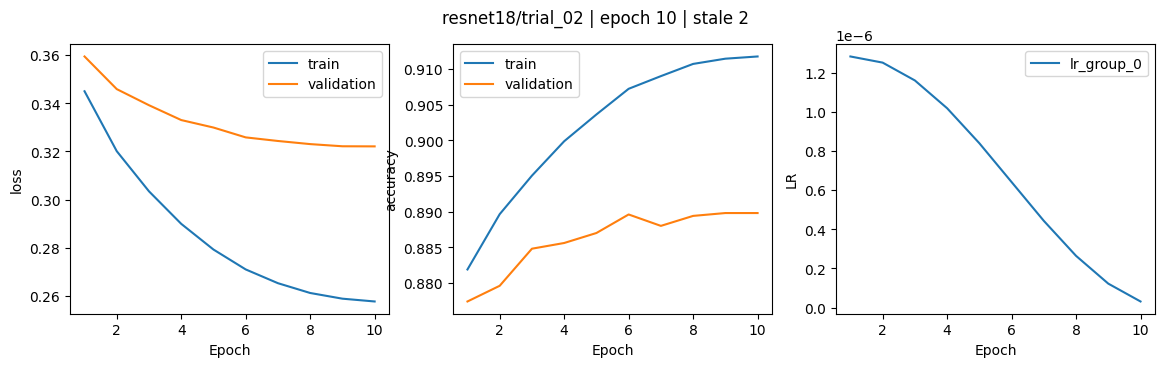

  train: 32128/45000
trial_02 epoch 2/10: train=0.8896, val=0.8796
  train: 32128/45000
trial_02 epoch 3/10: train=0.8950, val=0.8848
  train: 32128/45000
trial_02 epoch 4/10: train=0.8999, val=0.8856
  train: 32128/45000
trial_02 epoch 5/10: train=0.9036, val=0.8870
  train: 32128/45000
trial_02 epoch 6/10: train=0.9072, val=0.8896
  train: 32128/45000
trial_02 epoch 7/10: train=0.9090, val=0.8880
  train: 32128/45000
trial_02 epoch 8/10: train=0.9107, val=0.8894
  train: 32128/45000
trial_02 epoch 9/10: train=0.9114, val=0.8898
  train: 32128/45000
trial_02 epoch 10/10: train=0.9118, val=0.8898


[I 2026-10-30 10:58:58,498] Trial 2 finished with value: 0.32304659428596494 and parameters: {'lr': 1.28186559305949e-06}. Best is trial 0 with value: 0.263887745398283.


,number,value,datetime_start,datetime_complete,duration,params_lr,user_attrs_best_epoch,user_attrs_epochs_completed,state
0,0,0.263888,2026-10-30 10:01:48.113022,2026-10-30 10:24:09.002219,0 days 00:22:20.889197,0.000013,6,9,COMPLETE
1,1,2.303080,2026-10-30 10:24:09.044375,2026-10-30 10:34:05.380872,0 days 00:09:56.336497,0.000711,1,4,COMPLETE
2,2,0.323047,2026-10-30 10:34:05.414693,2026-10-30 10:58:58.487747,0 days 00:24:53.073054,0.000001,8,10,COMPLETE


,number,value,datetime_start,datetime_complete,duration,params_lr,user_attrs_best_epoch,user_attrs_epochs_completed,state
0,0,0.263888,2026-10-30 10:01:48.113022,2026-10-30 10:24:09.002219,0 days 00:22:20.889197,0.000013,6,9,COMPLETE
1,1,2.303080,2026-10-30 10:24:09.044375,2026-10-30 10:34:05.380872,0 days 00:09:56.336497,0.000711,1,4,COMPLETE
2,2,0.323047,2026-10-30 10:34:05.414693,2026-10-30 10:58:58.487747,0 days 00:24:53.073054,0.000001,8,10,COMPLETE


{'trial': 0, 'lr': 1.329291894316217e-05, 'validation_loss': 0.263887745398283}


In [10]:
try:
    resnet_selection=suite.search('resnet18')
finally:
    shutil.make_archive('/kaggle/working/lab02_standard_outputs','zip',WORK,'outputs')
display(pd.read_csv(RUN/'resnet18/trials.csv'));print(resnet_selection)


## 8. DenseNet121 head-only

Cùng head protocol, seed, batch và ngân sách như ResNet; classifier 10 lớp trên feature cache mới của DenseNet.

Stage: densenet121/head
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /kaggle/working/lab02_standard/data/pretrained/checkpoints/densenet121-a639ec97.pth


100%|##########| 30.8M/30.8M [00:00<00:00, 178MB/s]


densenet121 extract train: 64/45000
densenet121 extract train: 1664/45000
densenet121 extract train: 3264/45000
densenet121 extract train: 4864/45000
densenet121 extract train: 6464/45000
densenet121 extract train: 8064/45000
densenet121 extract train: 9664/45000
densenet121 extract train: 11264/45000
densenet121 extract train: 12864/45000
densenet121 extract train: 14464/45000
densenet121 extract train: 16064/45000
densenet121 extract train: 17664/45000
densenet121 extract train: 19264/45000
densenet121 extract train: 20864/45000
densenet121 extract train: 22464/45000
densenet121 extract train: 24064/45000
densenet121 extract train: 25664/45000
densenet121 extract train: 27264/45000
densenet121 extract train: 28864/45000
densenet121 extract train: 30464/45000
densenet121 extract train: 32064/45000
densenet121 extract train: 33664/45000
densenet121 extract train: 35264/45000
densenet121 extract train: 36864/45000
densenet121 extract train: 38464/45000
densenet121 extract train: 40064/4

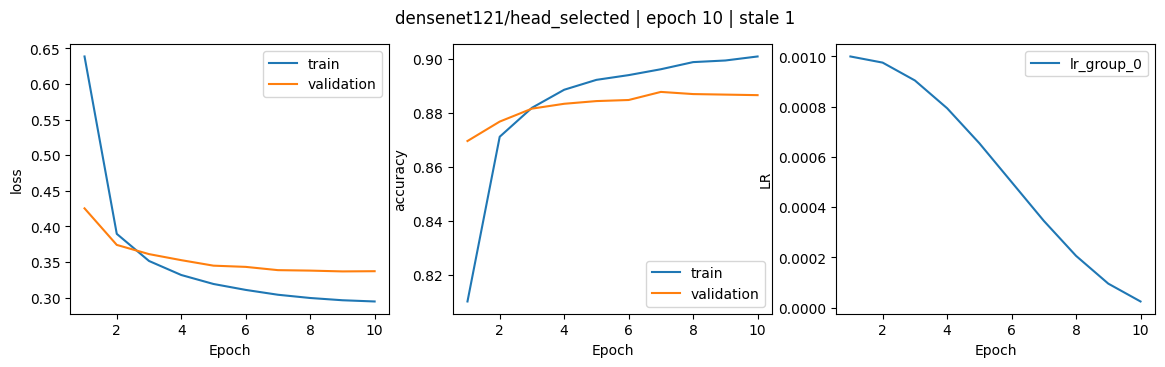

  train: 32128/45000
head_selected epoch 2/10: train=0.8712, val=0.8768
  train: 32128/45000
head_selected epoch 3/10: train=0.8819, val=0.8816
  train: 32128/45000
head_selected epoch 4/10: train=0.8886, val=0.8834
  train: 32128/45000
head_selected epoch 5/10: train=0.8923, val=0.8844
  train: 32128/45000
head_selected epoch 6/10: train=0.8940, val=0.8848
  train: 32128/45000
head_selected epoch 7/10: train=0.8962, val=0.8878
  train: 32128/45000
head_selected epoch 8/10: train=0.8988, val=0.8870
  train: 32128/45000
head_selected epoch 9/10: train=0.8994, val=0.8868
  train: 32128/45000
head_selected epoch 10/10: train=0.9009, val=0.8866
Head checkpoint locked: /kaggle/working/lab02_standard/outputs/runs/20261030T095916Z_standard_bb2ef6d8/densenet121/head_selected


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,epoch_seconds,train_pass_seconds,validation_seconds,train_images_per_second,lr_group_0
0,1,0.638625,0.810133,0.425276,0.8696,0.962505,0.897054,0.065421,50164.227201,0.001000
1,2,0.389467,0.871178,0.373949,0.8768,0.929839,0.861615,0.068049,52227.479484,0.000976
2,3,0.351380,0.881911,0.361019,0.8816,0.913938,0.851359,0.062331,52856.694745,0.000905
3,4,0.331680,0.888600,0.352520,0.8834,0.918220,0.854549,0.063425,52659.369298,0.000794
4,5,0.319060,0.892267,0.344788,0.8844,0.942842,0.879333,0.063302,51175.142531,0.000655
5,6,0.310739,0.894022,0.343080,0.8848,0.942379,0.878407,0.063800,51229.126719,0.000500
6,7,0.303934,0.896200,0.338496,0.8878,0.983587,0.918970,0.064412,48967.872059,0.000345
7,8,0.299374,0.898844,0.337841,0.8870,0.929829,0.866725,0.062879,51919.560052,0.000206
8,9,0.296207,0.899444,0.336711,0.8868,0.934077,0.870024,0.063815,51722.728635,0.000095
9,10,0.294489,0.900933,0.337008,0.8866,0.927456,0.864411,0.062837,52058.583935,0.000024


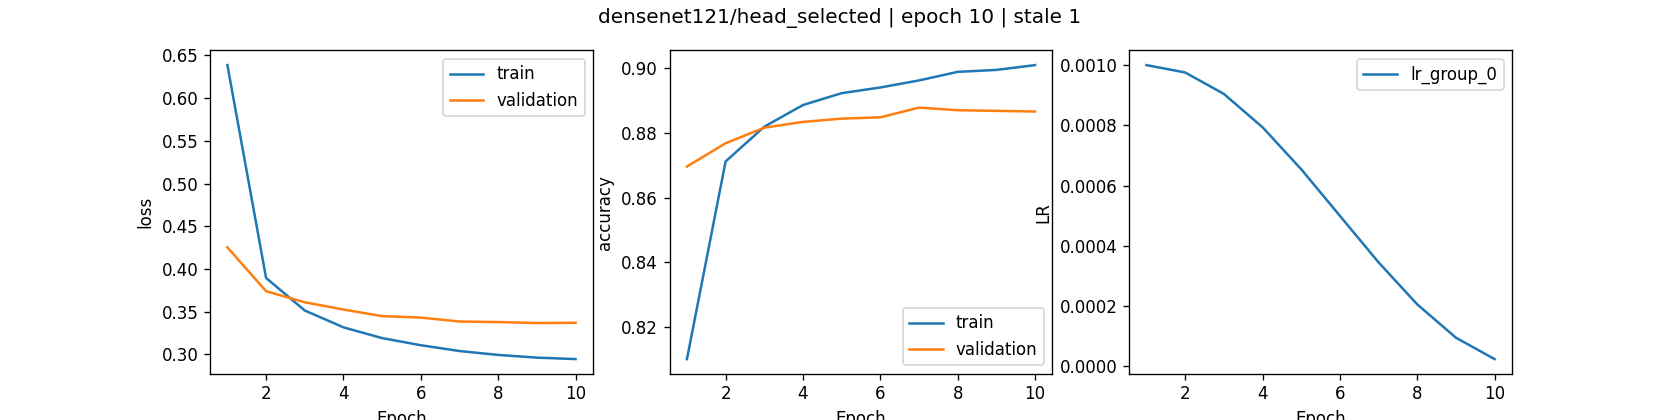

In [11]:
try:
    dense_head=suite.head('densenet121')
finally:
    shutil.make_archive('/kaggle/working/lab02_standard_outputs','zip',WORK,'outputs')
display(pd.read_csv(dense_head/'history.csv'))
display(Image(filename=str(dense_head/'learning_curves.png')))


## 9. DenseNet121 fine-tune và Optuna

Mở block4+norm5+classifier, các phần trước đóng băng. Không mở block3/transition3. Cùng 3 trial và tiêu chí loss như ResNet.

Stage: densenet121/search


[I 2026-10-30 11:03:47,435] A new study created in RDB with name: densenet121


  train: 32128/45000
trial_00 epoch 1/10: train=0.9016, val=0.8930


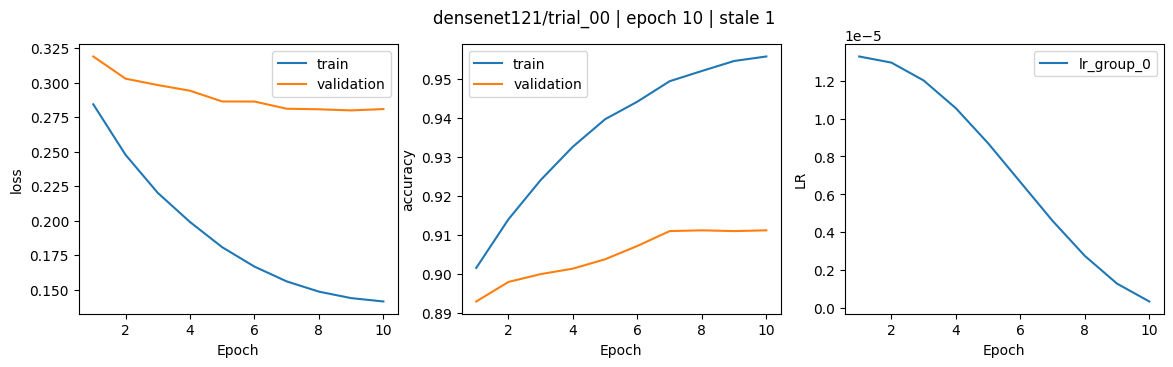

  train: 32128/45000
trial_00 epoch 2/10: train=0.9140, val=0.8980
  train: 32128/45000
trial_00 epoch 3/10: train=0.9241, val=0.9000
  train: 32128/45000
trial_00 epoch 4/10: train=0.9326, val=0.9014
  train: 32128/45000
trial_00 epoch 5/10: train=0.9396, val=0.9038
  train: 32128/45000
trial_00 epoch 6/10: train=0.9441, val=0.9072
  train: 32128/45000
trial_00 epoch 7/10: train=0.9493, val=0.9110
  train: 32128/45000
trial_00 epoch 8/10: train=0.9520, val=0.9112
  train: 32128/45000
trial_00 epoch 9/10: train=0.9545, val=0.9110
  train: 32128/45000
trial_00 epoch 10/10: train=0.9557, val=0.9112


[I 2026-10-30 11:44:20,249] Trial 0 finished with value: 0.27979673105180264 and parameters: {'lr': 1.329291894316217e-05}. Best is trial 0 with value: 0.27979673105180264.


,number,value,datetime_start,datetime_complete,duration,params_lr,user_attrs_best_epoch,user_attrs_epochs_completed,state
0,0,0.279797,2026-10-30 11:03:47.442749,2026-10-30 11:44:20.235752,0 days 00:40:32.793003,0.000013,9,10,COMPLETE


  train: 32128/45000
trial_01 epoch 1/10: train=0.8591, val=0.9030


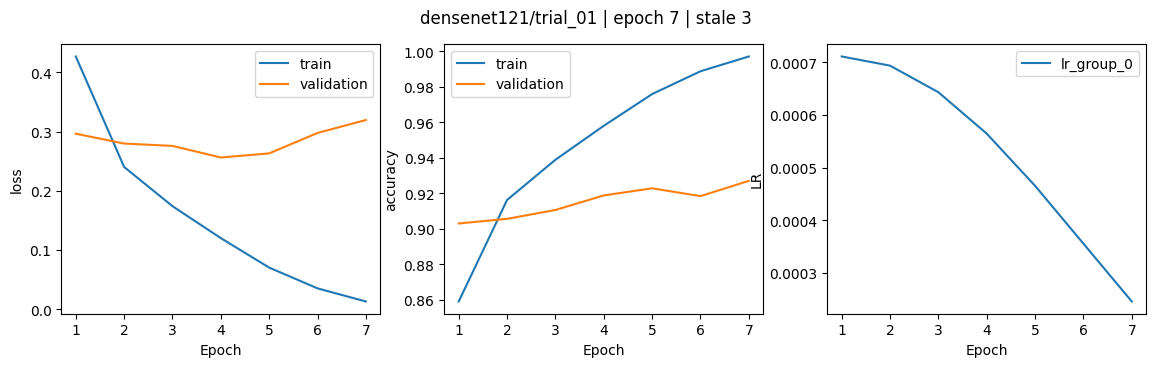

  train: 32128/45000
trial_01 epoch 2/10: train=0.9162, val=0.9056
  train: 32128/45000
trial_01 epoch 3/10: train=0.9389, val=0.9106
  train: 32128/45000
trial_01 epoch 4/10: train=0.9580, val=0.9188
  train: 32128/45000
trial_01 epoch 5/10: train=0.9759, val=0.9228
  train: 32128/45000
trial_01 epoch 6/10: train=0.9887, val=0.9184
  train: 32128/45000
trial_01 epoch 7/10: train=0.9971, val=0.9270


[I 2026-10-30 12:12:40,964] Trial 1 finished with value: 0.25635199811458587 and parameters: {'lr': 0.0007114476009343421}. Best is trial 1 with value: 0.25635199811458587.


,number,value,datetime_start,datetime_complete,duration,params_lr,user_attrs_best_epoch,user_attrs_epochs_completed,state
0,0,0.279797,2026-10-30 11:03:47.442749,2026-10-30 11:44:20.235752,0 days 00:40:32.793003,0.000013,9,10,COMPLETE
1,1,0.256352,2026-10-30 11:44:20.273466,2026-10-30 12:12:40.952099,0 days 00:28:20.678633,0.000711,4,7,COMPLETE


  train: 32128/45000
trial_02 epoch 1/10: train=0.8526, val=0.8918


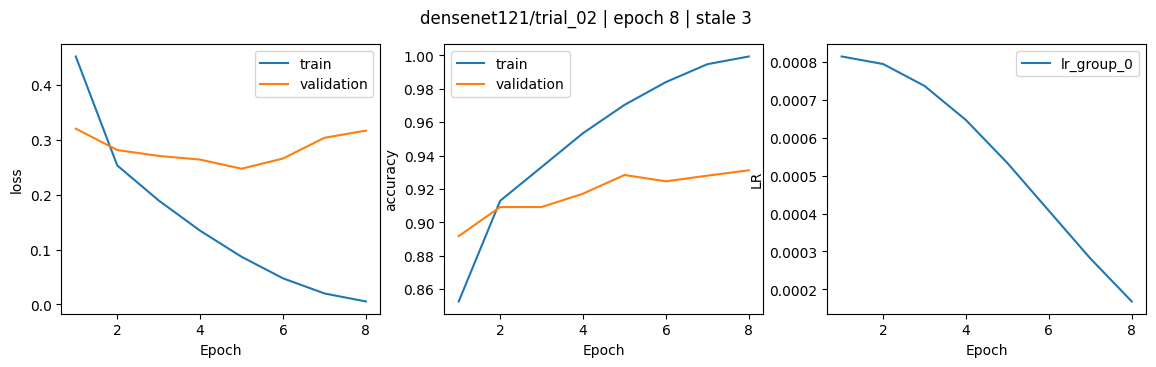

  train: 32128/45000
trial_02 epoch 2/10: train=0.9129, val=0.9092
  train: 32128/45000
trial_02 epoch 3/10: train=0.9332, val=0.9092
  train: 32128/45000
trial_02 epoch 4/10: train=0.9535, val=0.9172
  train: 32128/45000
trial_02 epoch 5/10: train=0.9704, val=0.9284
  train: 32128/45000
trial_02 epoch 6/10: train=0.9840, val=0.9246
  train: 32128/45000
trial_02 epoch 7/10: train=0.9948, val=0.9280
  train: 32128/45000
trial_02 epoch 8/10: train=0.9994, val=0.9312


[I 2026-10-30 12:45:04,630] Trial 2 finished with value: 0.24750953695774078 and parameters: {'lr': 0.0008146824972620024}. Best is trial 2 with value: 0.24750953695774078.


,number,value,datetime_start,datetime_complete,duration,params_lr,user_attrs_best_epoch,user_attrs_epochs_completed,state
0,0,0.279797,2026-10-30 11:03:47.442749,2026-10-30 11:44:20.235752,0 days 00:40:32.793003,0.000013,9,10,COMPLETE
1,1,0.256352,2026-10-30 11:44:20.273466,2026-10-30 12:12:40.952099,0 days 00:28:20.678633,0.000711,4,7,COMPLETE
2,2,0.247510,2026-10-30 12:12:40.987035,2026-10-30 12:45:04.618811,0 days 00:32:23.631776,0.000815,5,8,COMPLETE


,number,value,datetime_start,datetime_complete,duration,params_lr,user_attrs_best_epoch,user_attrs_epochs_completed,state
0,0,0.279797,2026-10-30 11:03:47.442749,2026-10-30 11:44:20.235752,0 days 00:40:32.793003,0.000013,9,10,COMPLETE
1,1,0.256352,2026-10-30 11:44:20.273466,2026-10-30 12:12:40.952099,0 days 00:28:20.678633,0.000711,4,7,COMPLETE
2,2,0.247510,2026-10-30 12:12:40.987035,2026-10-30 12:45:04.618811,0 days 00:32:23.631776,0.000815,5,8,COMPLETE


{'trial': 2, 'lr': 0.0008146824972620024, 'validation_loss': 0.24750953695774078}


In [12]:
try:
    dense_selection=suite.search('densenet121')
finally:
    shutil.make_archive('/kaggle/working/lab02_standard_outputs','zip',WORK,'outputs')
display(pd.read_csv(RUN/'densenet121/trials.csv'));print(dense_selection)


## 10. Bốn điều kiện: test, trực quan và full-test sau load

Lúc này cả hai study đã khóa winner. Với từng model, đánh giá head và fine-tune, load lại bằng model instance độc lập và predict đủ 10.000 test. Confusion chứa số đếm; ROC/PR OvR hai panel mỗi điều kiện. Lưới 8 đúng/8 sai không đại diện accuracy. AP khác trapezoidal PR-AUC.

Stage: resnet18/test
resnet18 head


,test metrics
test_samples,10000.000000
accuracy,0.858000
macro_f1,0.857751
macro_precision,0.858018
macro_recall,0.858000
loss,0.402405


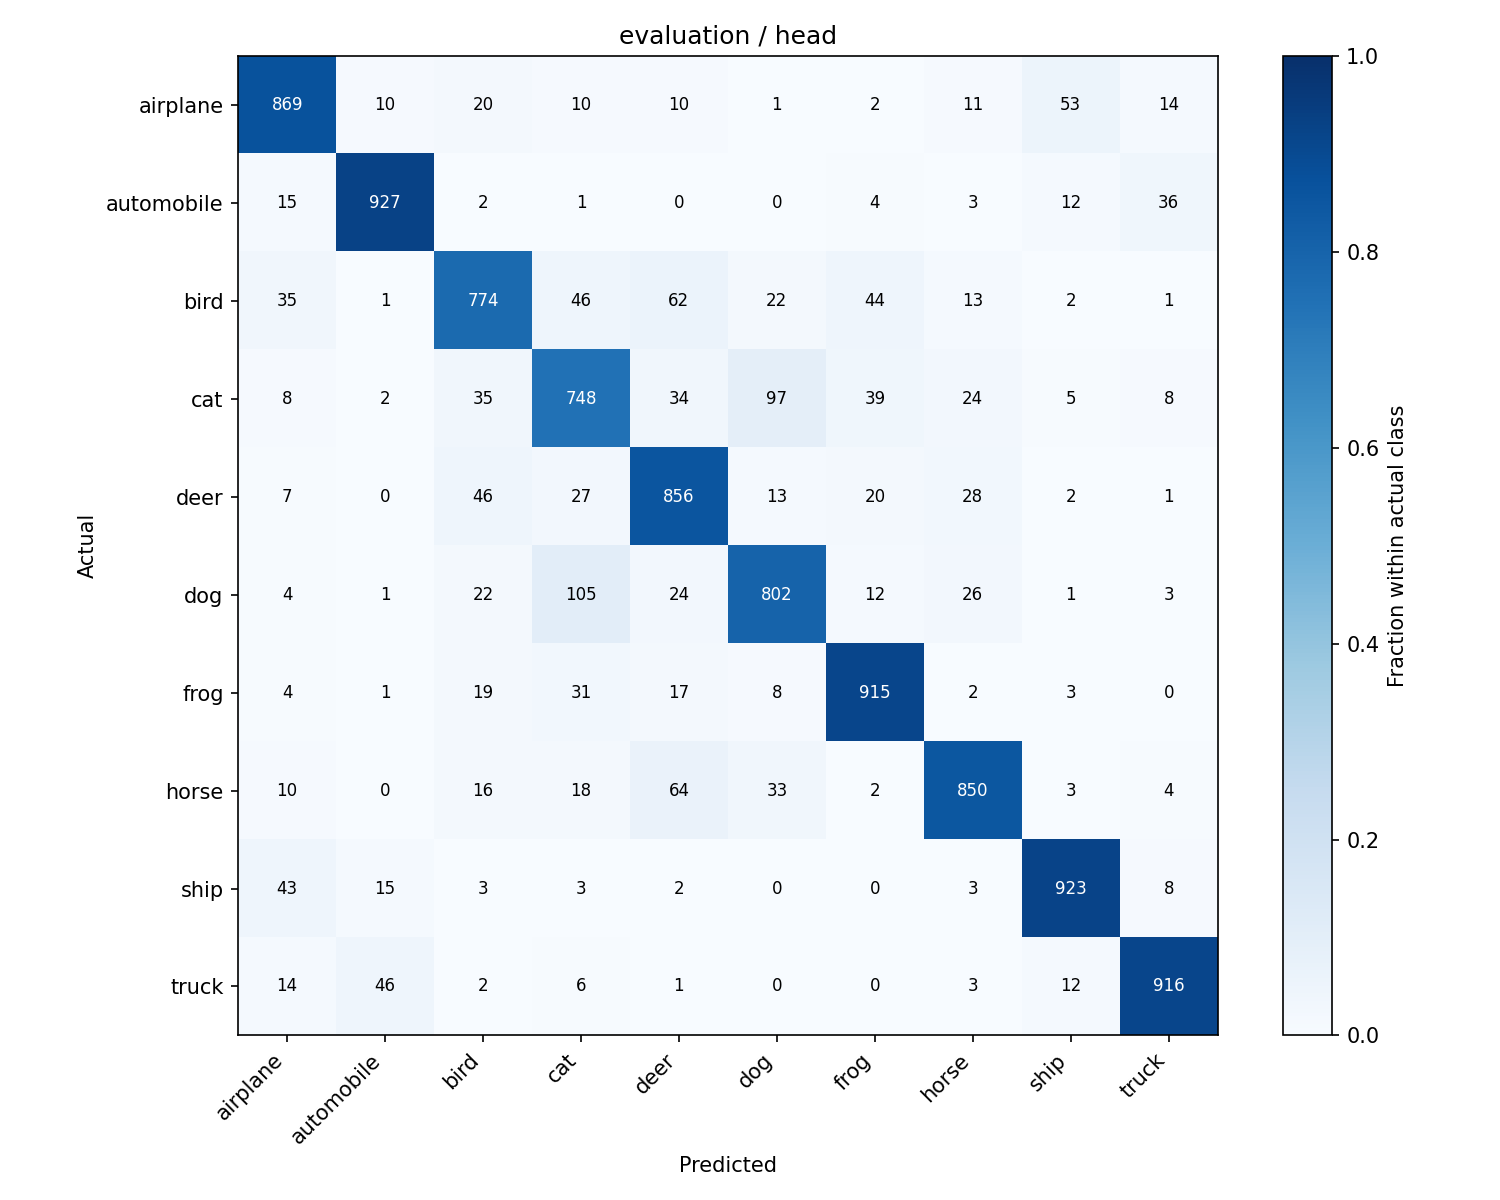

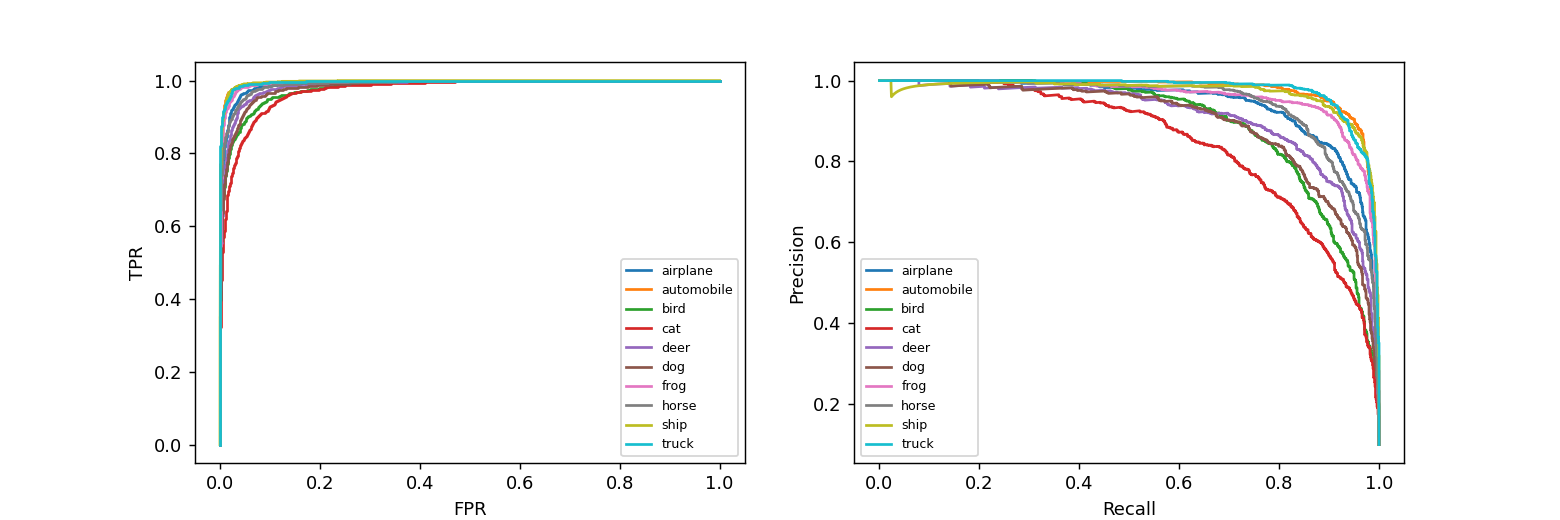

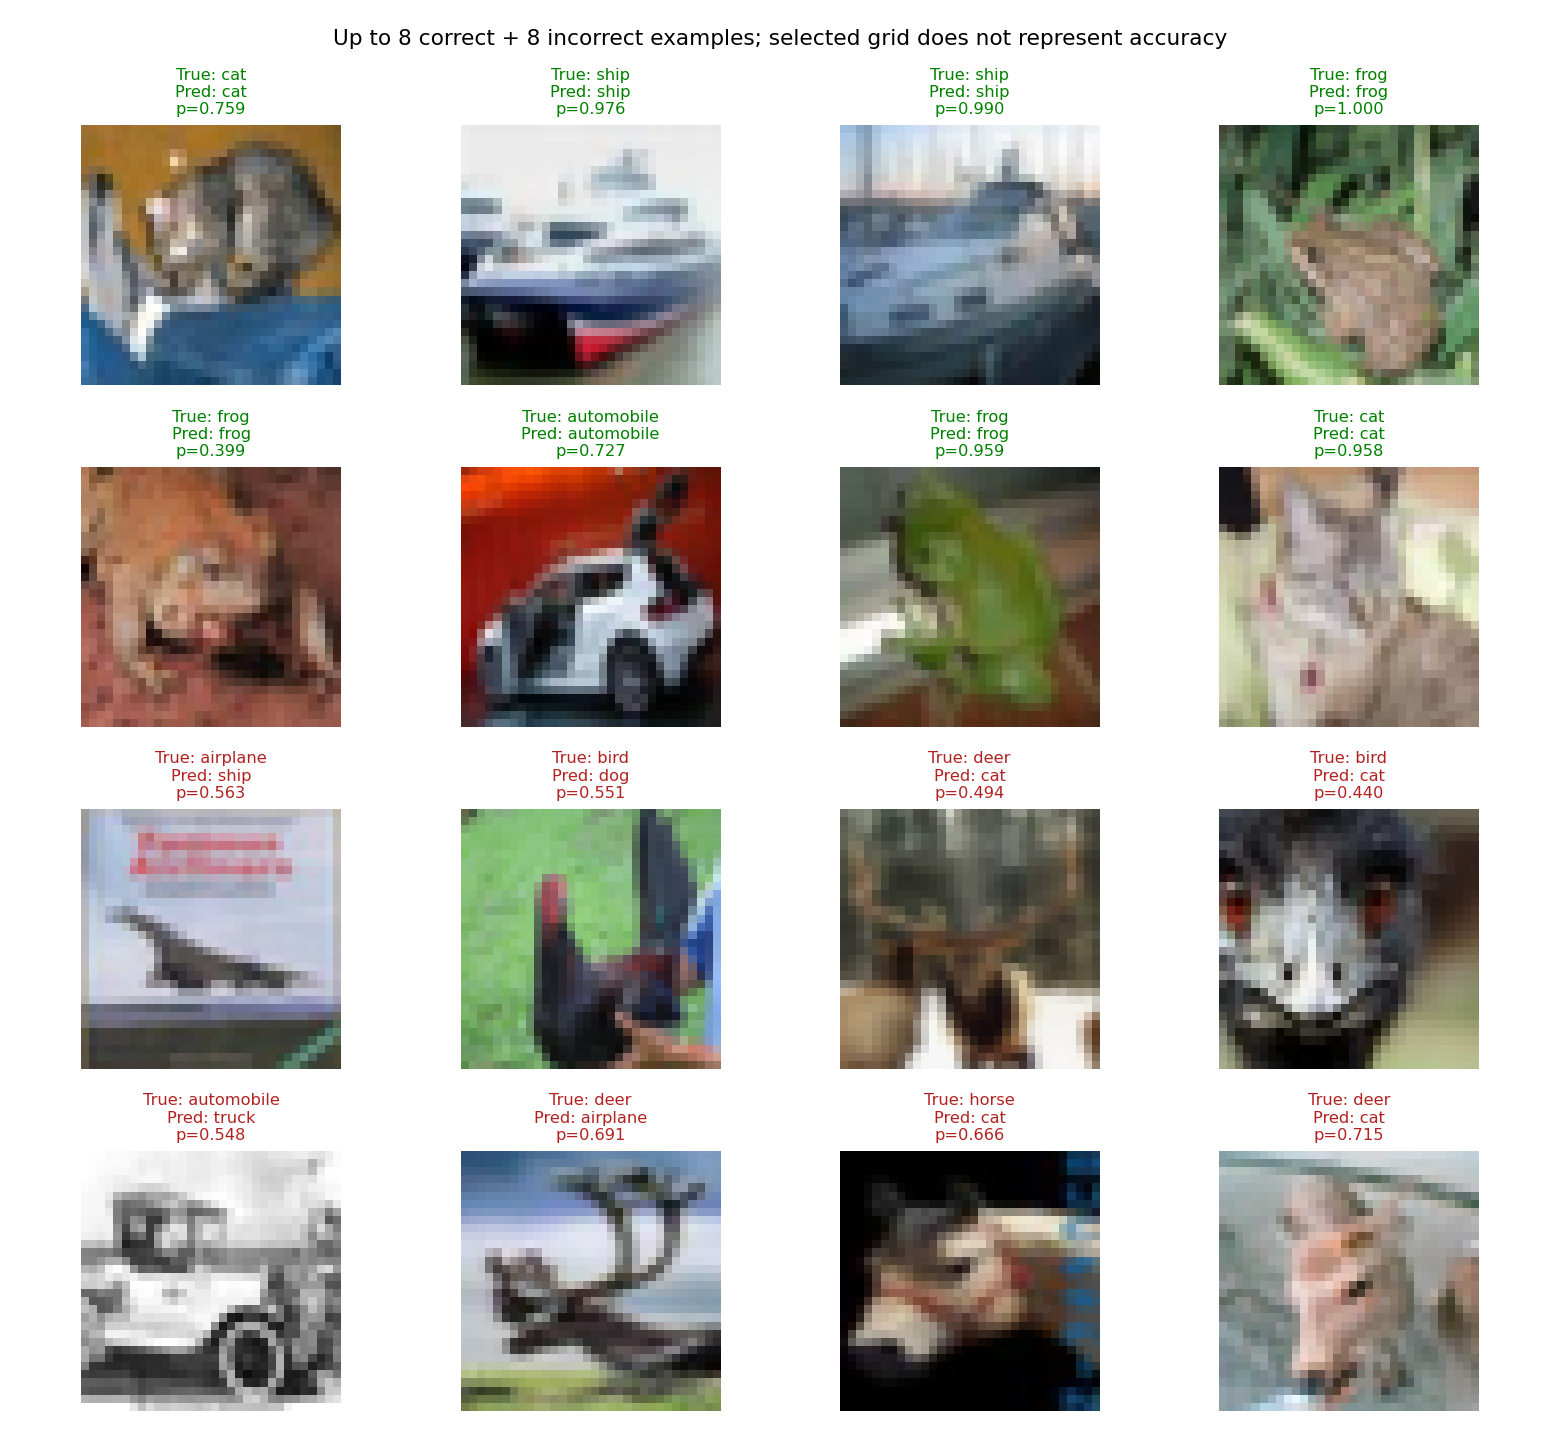

,Unnamed: 0,precision,recall,f1-score,support
0,airplane,0.861249,0.869,0.865107,1000.000
1,automobile,0.924227,0.927,0.925612,1000.000
2,bird,0.824281,0.774,0.798350,1000.000
3,cat,0.751759,0.748,0.749875,1000.000
4,deer,0.800000,0.856,0.827053,1000.000
5,dog,0.821721,0.802,0.811741,1000.000
6,frog,0.881503,0.915,0.897939,1000.000
7,horse,0.882658,0.850,0.866021,1000.000
8,ship,0.908465,0.923,0.915675,1000.000
9,truck,0.924319,0.916,0.920141,1000.000


,class,roc_auc,average_precision
0,airplane,0.991351,0.943933
1,automobile,0.996408,0.977921
2,bird,0.980794,0.896552
3,cat,0.973353,0.848569
4,deer,0.986407,0.910478
5,dog,0.984109,0.899288
6,frog,0.994653,0.961051
7,horse,0.990831,0.943903
8,ship,0.996617,0.970985
9,truck,0.996821,0.978597


Reload verification: {'passed': True, 'samples': 10000, 'max_probability_error': 0.0}


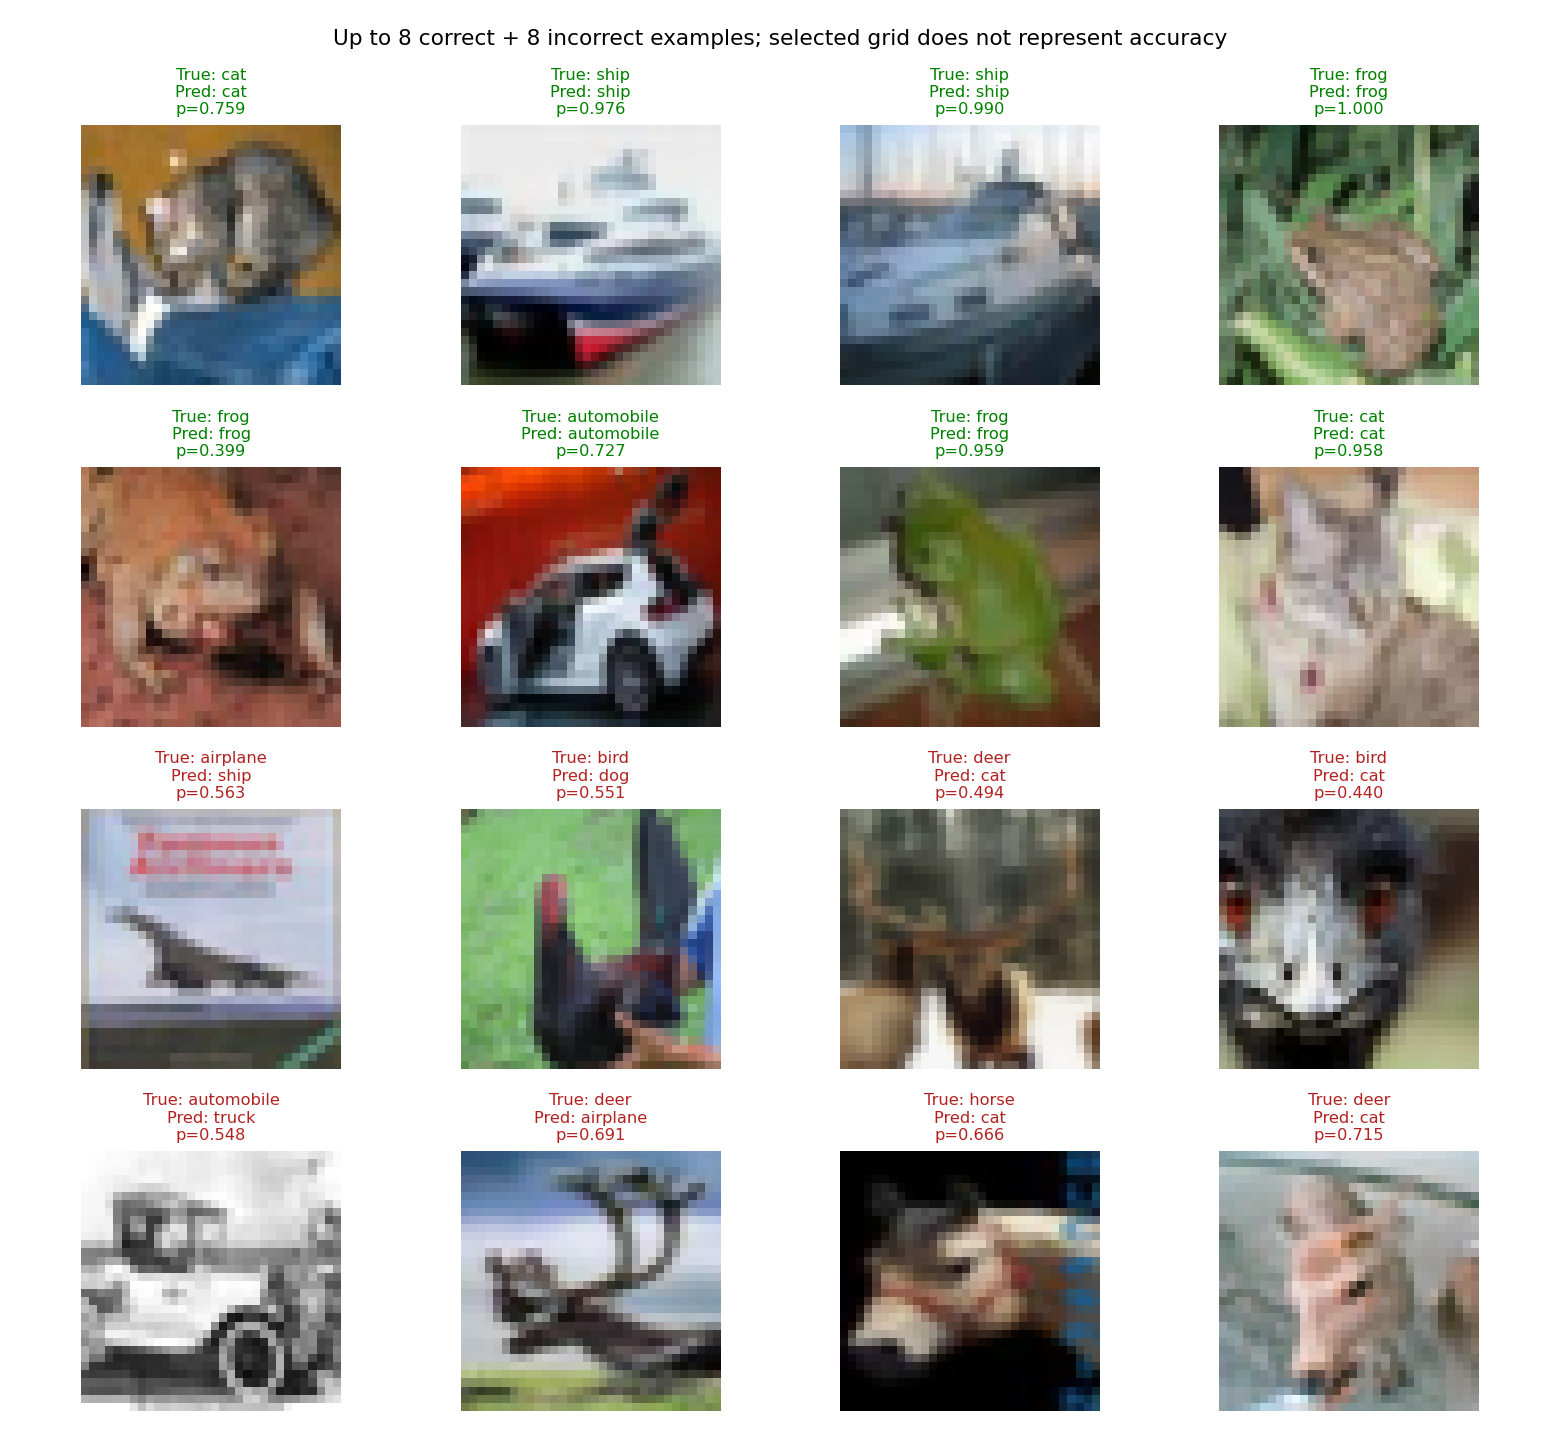

,index,true,predicted,probability
0,0,3,3,0.759247
1,1,8,8,0.976015
2,2,8,8,0.990478
3,4,6,6,0.999807
4,5,6,6,0.399133
5,6,1,1,0.727144
6,7,6,6,0.959225
7,8,3,3,0.958358
8,3,0,8,0.563260
9,25,2,5,0.551086


resnet18 finetune


,test metrics
test_samples,10000.000000
accuracy,0.910800
macro_f1,0.910768
macro_precision,0.911151
macro_recall,0.910800
loss,0.284503


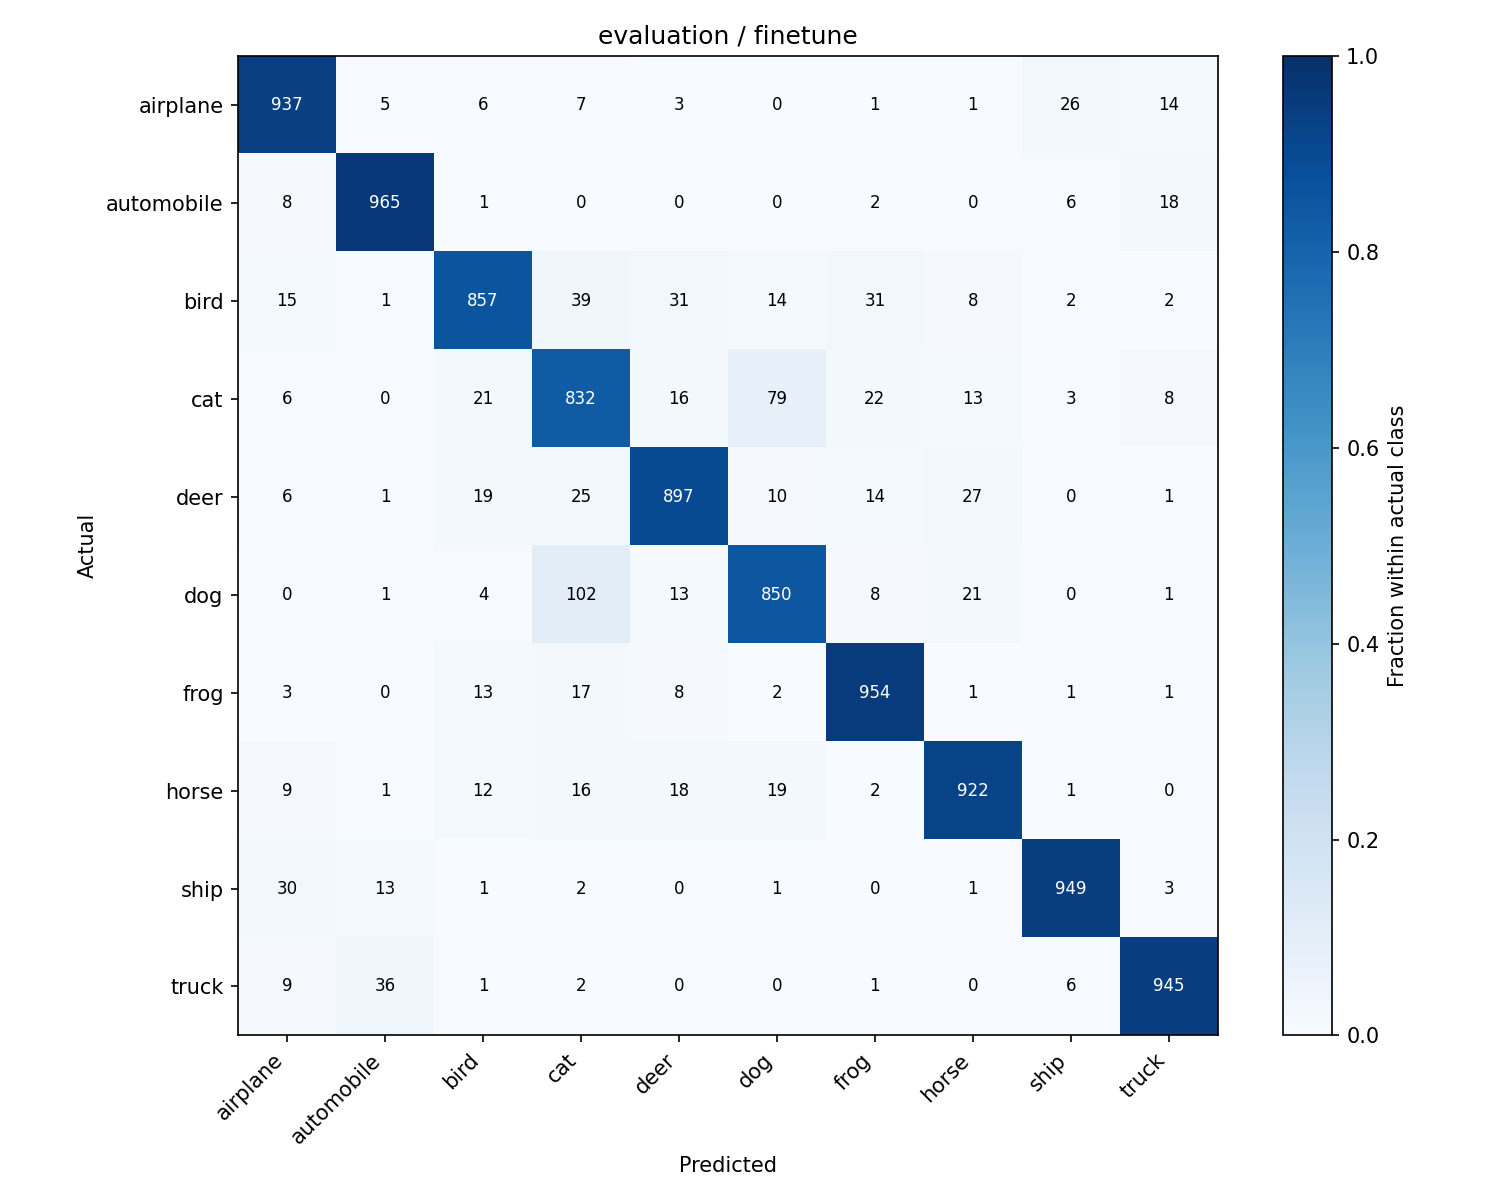

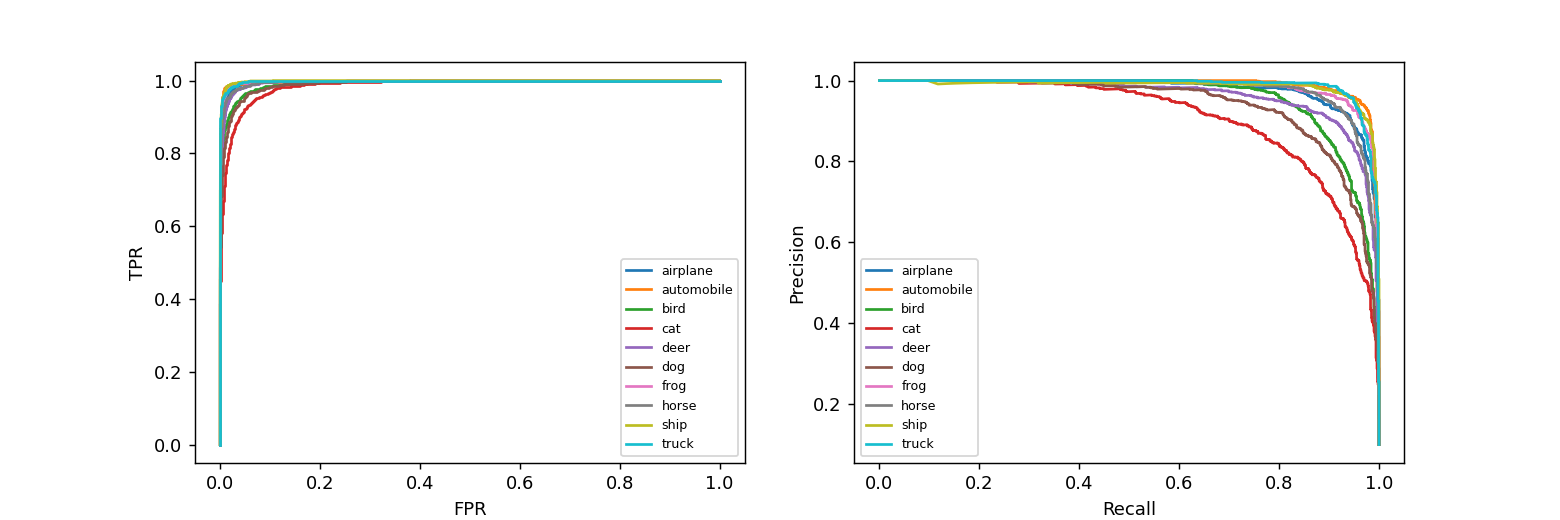

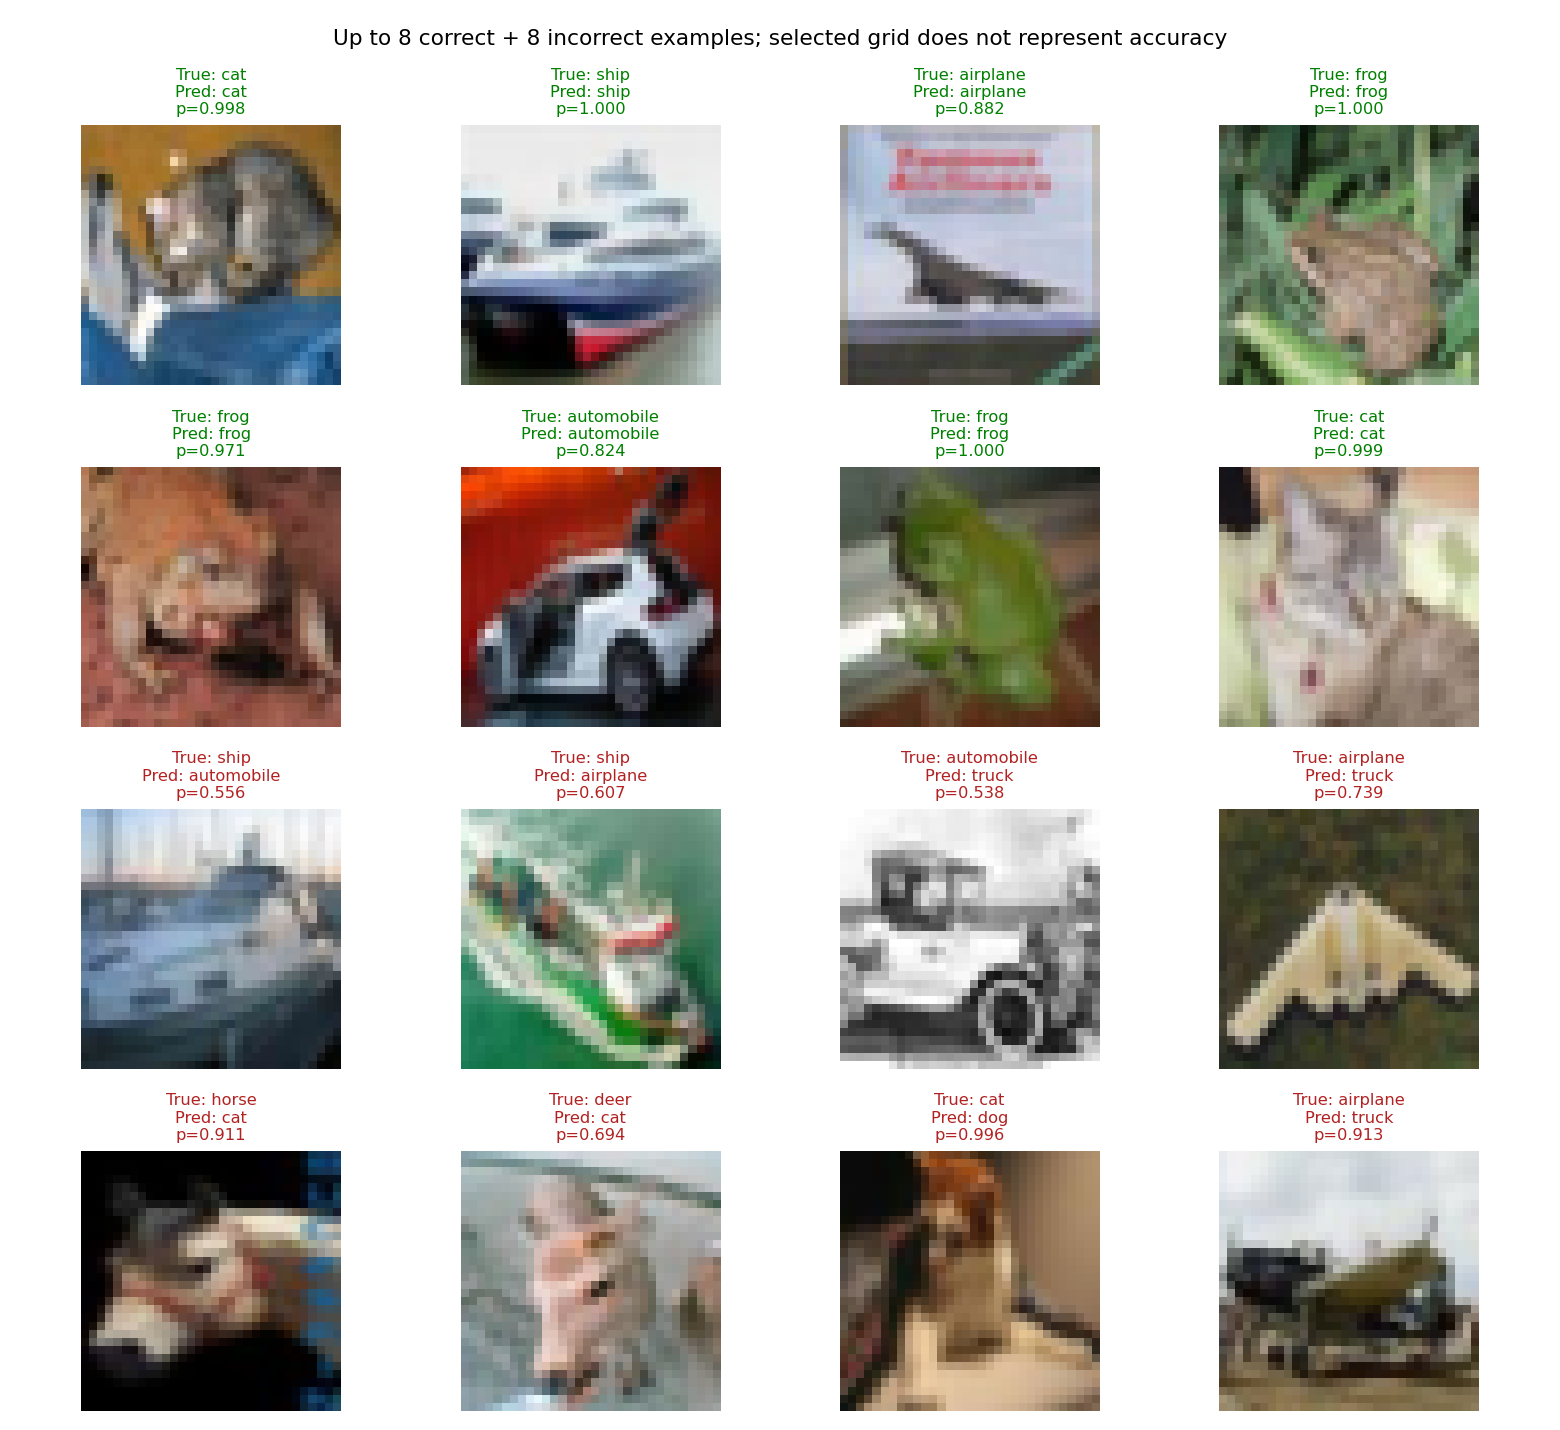

,Unnamed: 0,precision,recall,f1-score,support
0,airplane,0.915934,0.9370,0.926347,1000.0000
1,automobile,0.943304,0.9650,0.954029,1000.0000
2,bird,0.916578,0.8570,0.885788,1000.0000
3,cat,0.798464,0.8320,0.814887,1000.0000
4,deer,0.909736,0.8970,0.903323,1000.0000
5,dog,0.871795,0.8500,0.860759,1000.0000
6,frog,0.921739,0.9540,0.937592,1000.0000
7,horse,0.927565,0.9220,0.924774,1000.0000
8,ship,0.954728,0.9490,0.951856,1000.0000
9,truck,0.951662,0.9450,0.948319,1000.0000


,class,roc_auc,average_precision
0,airplane,0.996660,0.977786
1,automobile,0.998429,0.989951
2,bird,0.992787,0.957286
3,cat,0.985518,0.907950
4,deer,0.994849,0.962809
5,dog,0.990888,0.940053
6,frog,0.998197,0.985481
7,horse,0.997025,0.978958
8,ship,0.998567,0.986385
9,truck,0.998260,0.988646


Reload verification: {'passed': True, 'samples': 10000, 'max_probability_error': 0.0}


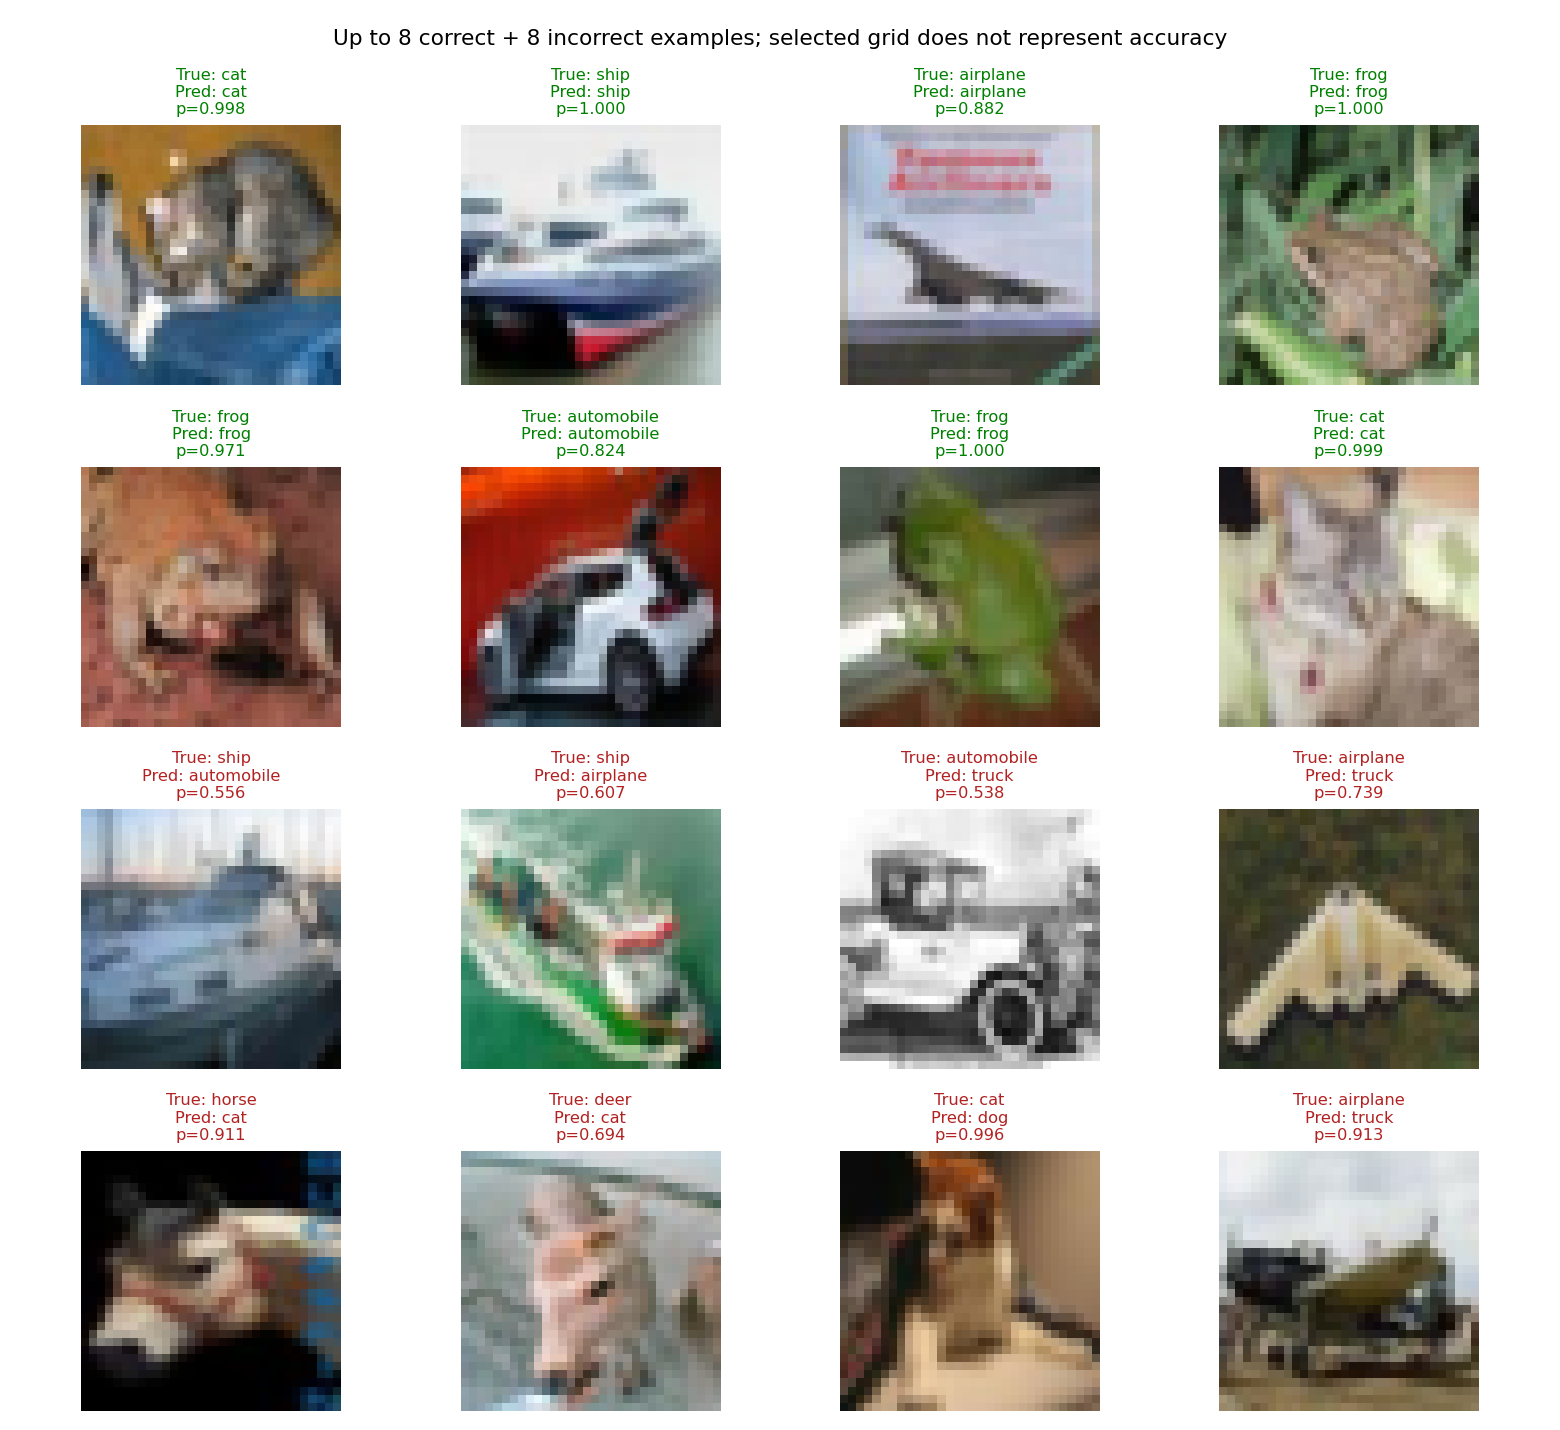

,index,true,predicted,probability
0,0,3,3,0.998089
1,1,8,8,0.999937
2,3,0,0,0.882049
3,4,6,6,1.000000
4,5,6,6,0.971382
5,6,1,1,0.824175
6,7,6,6,0.999992
7,8,3,3,0.998949
8,2,8,1,0.555604
9,15,8,0,0.606727


Stage: densenet121/test
densenet121 head


,test metrics
test_samples,10000.000000
accuracy,0.880500
macro_f1,0.880326
macro_precision,0.880442
macro_recall,0.880500
loss,0.344923


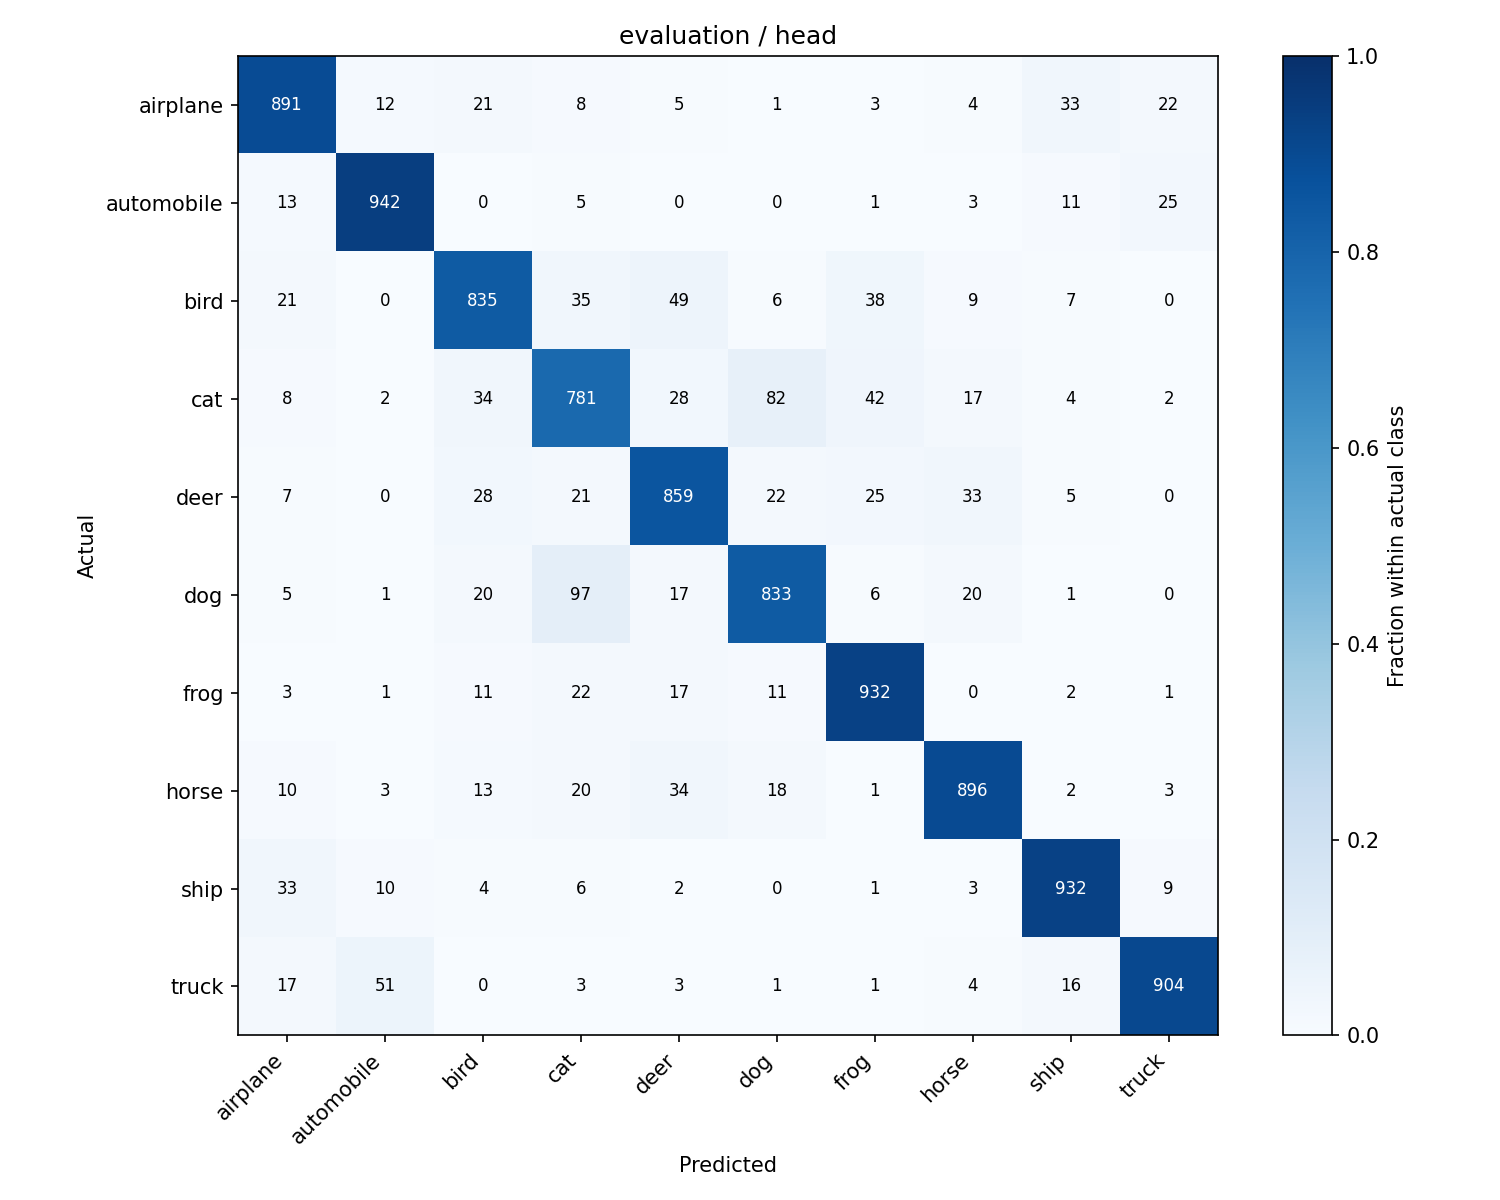

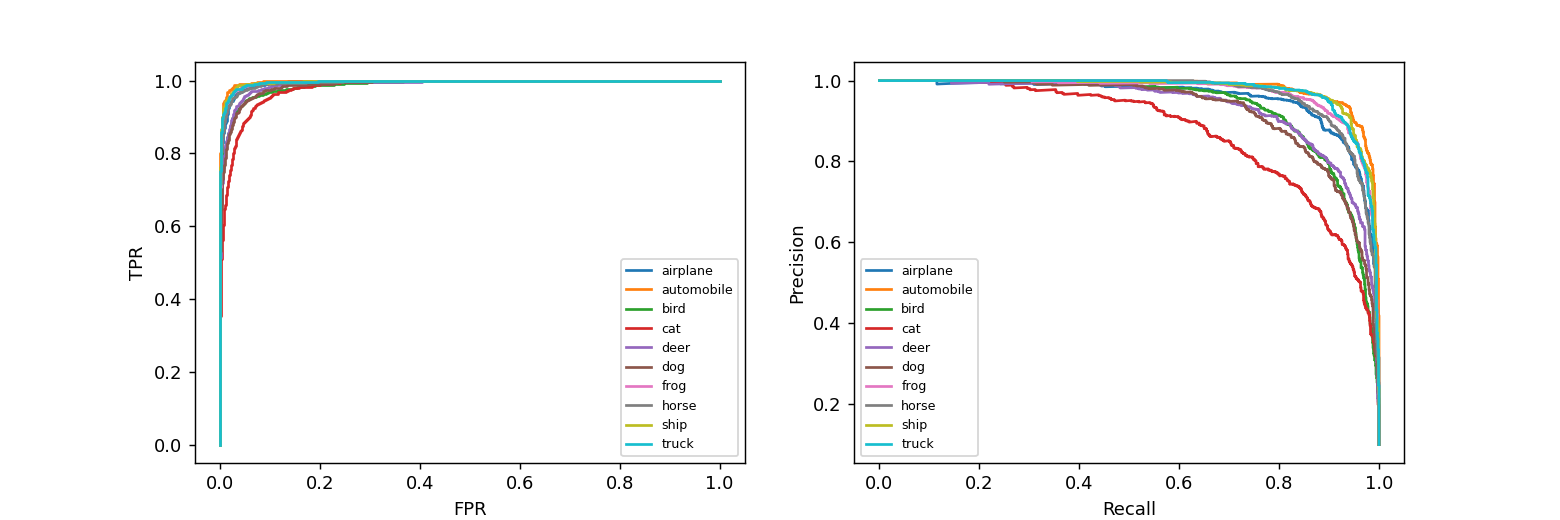

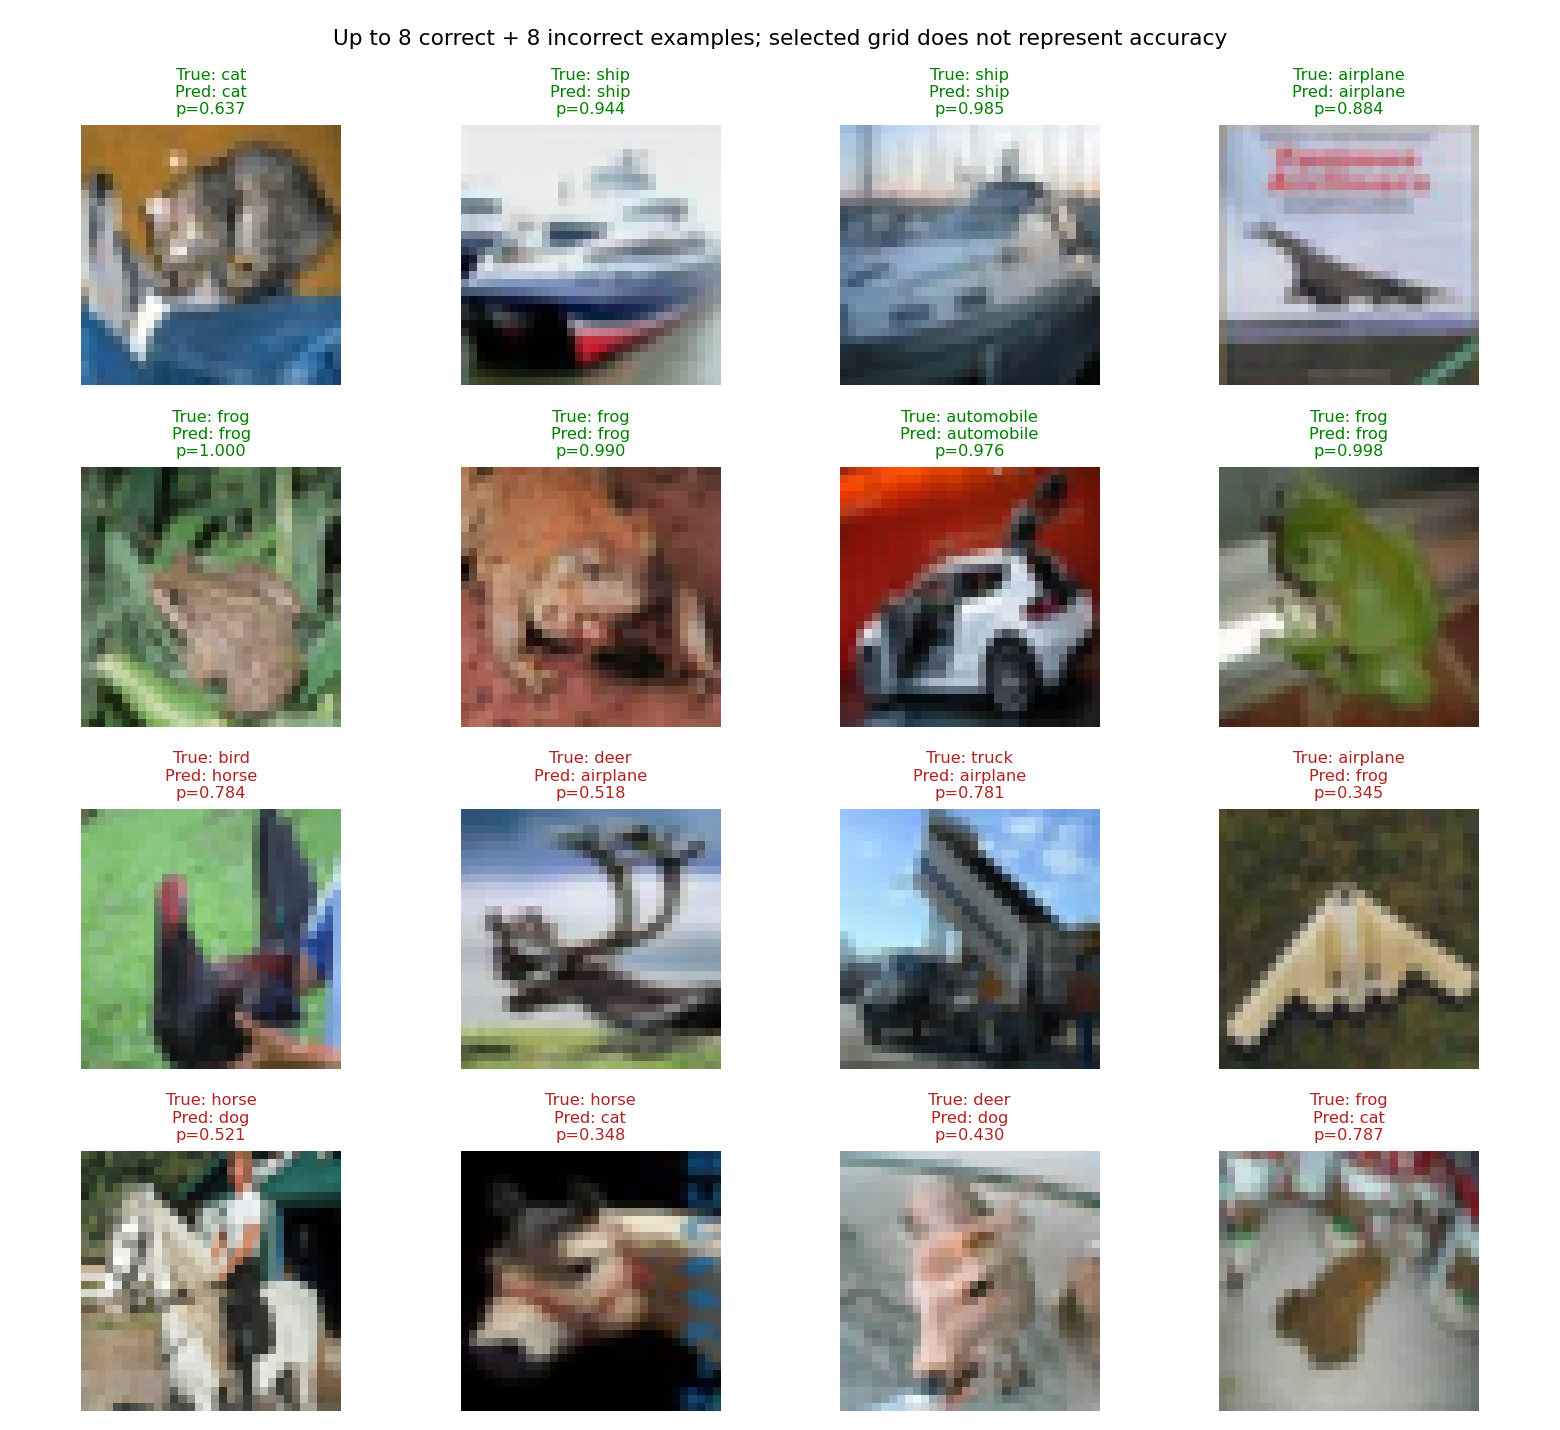

,Unnamed: 0,precision,recall,f1-score,support
0,airplane,0.883929,0.8910,0.887450,1000.0000
1,automobile,0.921722,0.9420,0.931751,1000.0000
2,bird,0.864389,0.8350,0.849440,1000.0000
3,cat,0.782565,0.7810,0.781782,1000.0000
4,deer,0.847140,0.8590,0.853029,1000.0000
5,dog,0.855236,0.8330,0.843972,1000.0000
6,frog,0.887619,0.9320,0.909268,1000.0000
7,horse,0.905966,0.8960,0.900955,1000.0000
8,ship,0.920039,0.9320,0.925981,1000.0000
9,truck,0.935818,0.9040,0.919634,1000.0000


,class,roc_auc,average_precision
0,airplane,0.994459,0.957460
1,automobile,0.997672,0.981883
2,bird,0.987766,0.933877
3,cat,0.980563,0.875745
4,deer,0.989764,0.934267
5,dog,0.988110,0.926939
6,frog,0.995833,0.971429
7,horse,0.994441,0.966713
8,ship,0.996643,0.977963
9,truck,0.996225,0.976125


Reload verification: {'passed': True, 'samples': 10000, 'max_probability_error': 0.0}


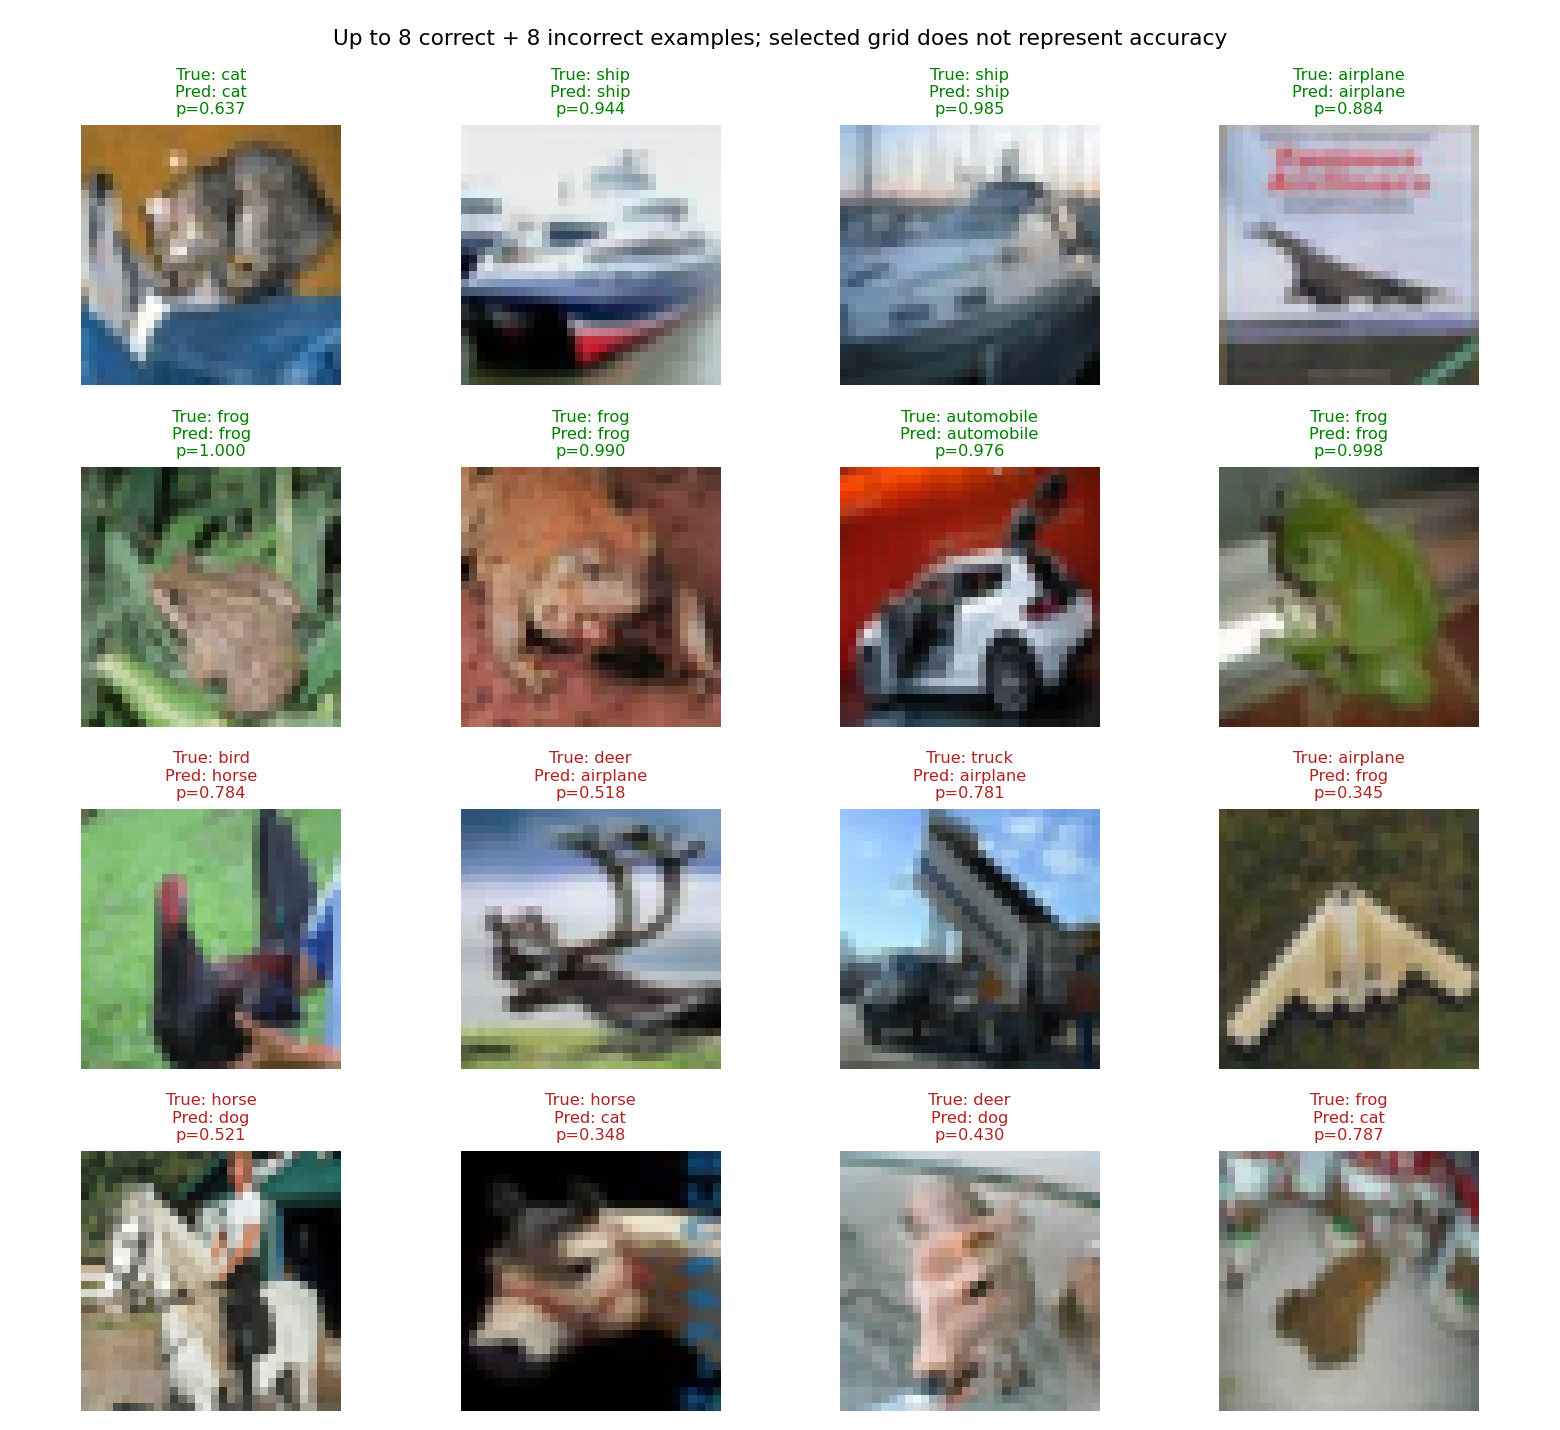

,index,true,predicted,probability
0,0,3,3,0.637126
1,1,8,8,0.943600
2,2,8,8,0.984930
3,3,0,0,0.884091
4,4,6,6,0.999998
5,5,6,6,0.989933
6,6,1,1,0.976094
7,7,6,6,0.998063
8,25,2,7,0.783633
9,40,4,0,0.518231


densenet121 finetune


,test metrics
test_samples,10000.000000
accuracy,0.923900
macro_f1,0.923764
macro_precision,0.924034
macro_recall,0.923900
loss,0.255533


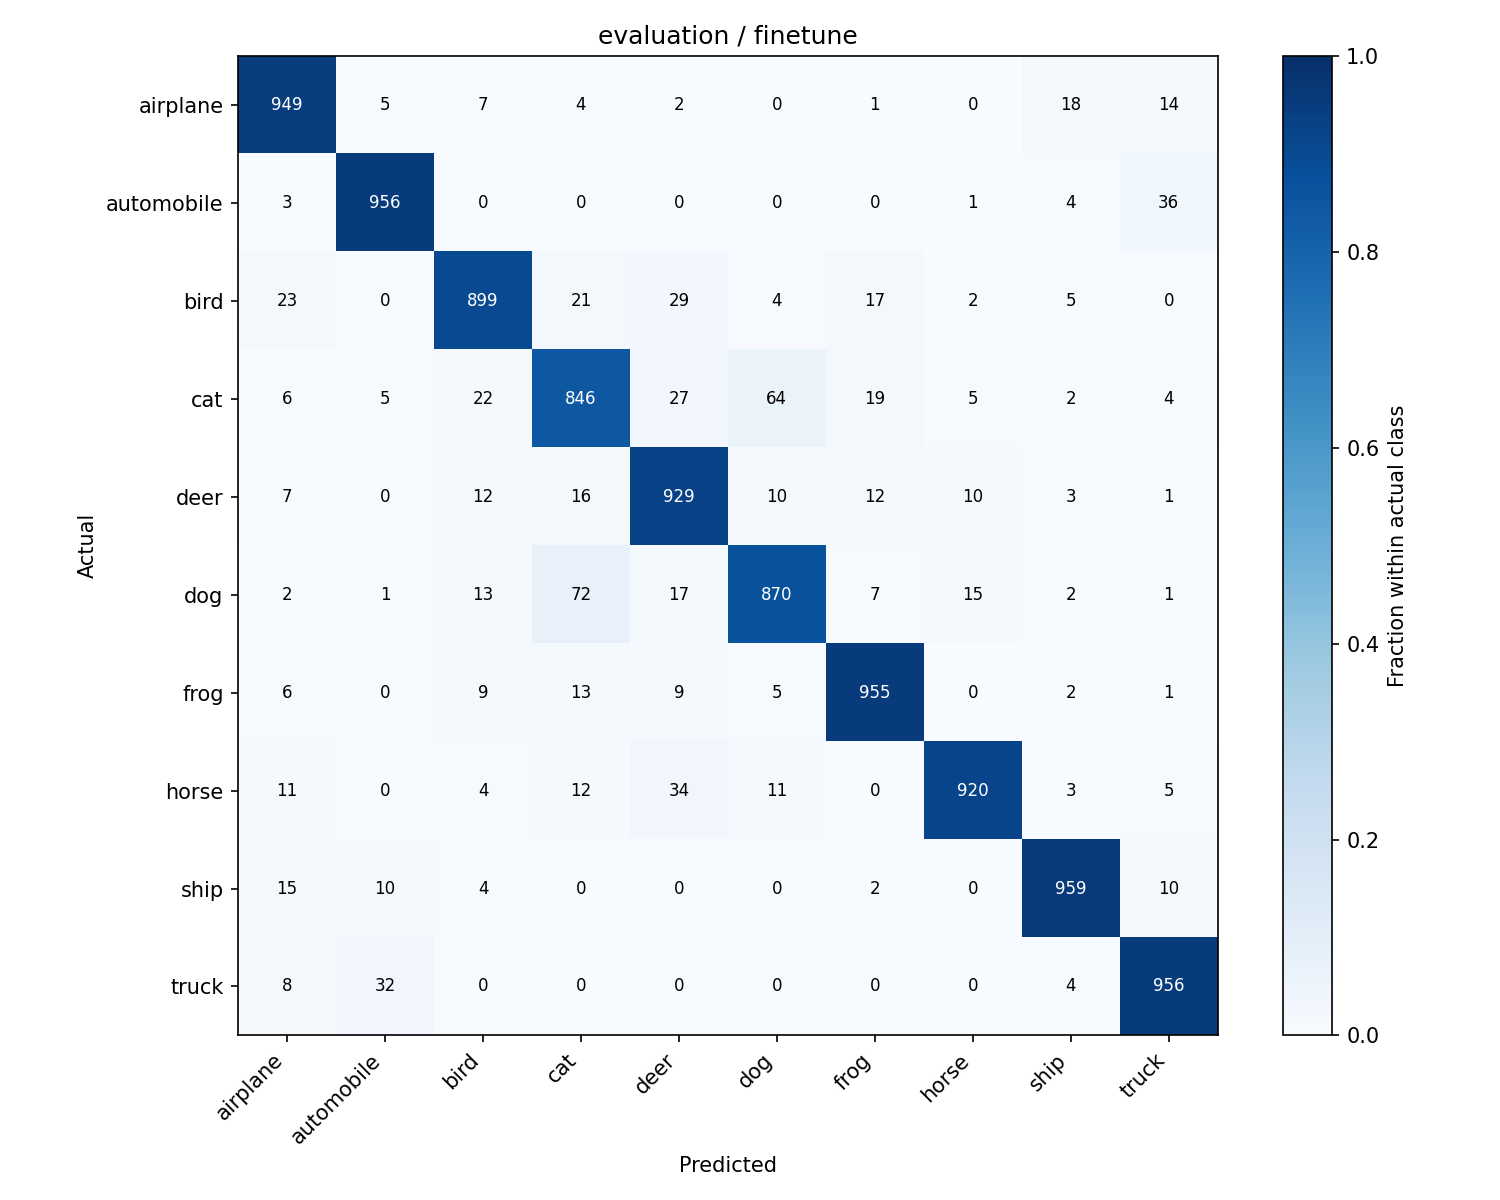

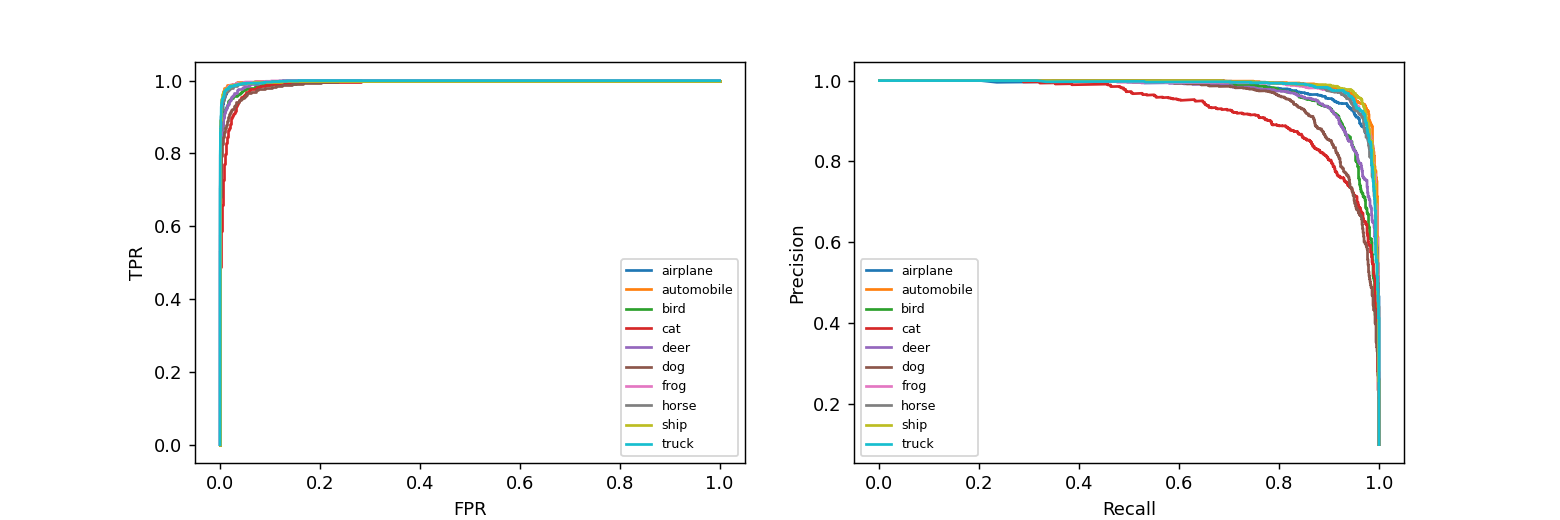

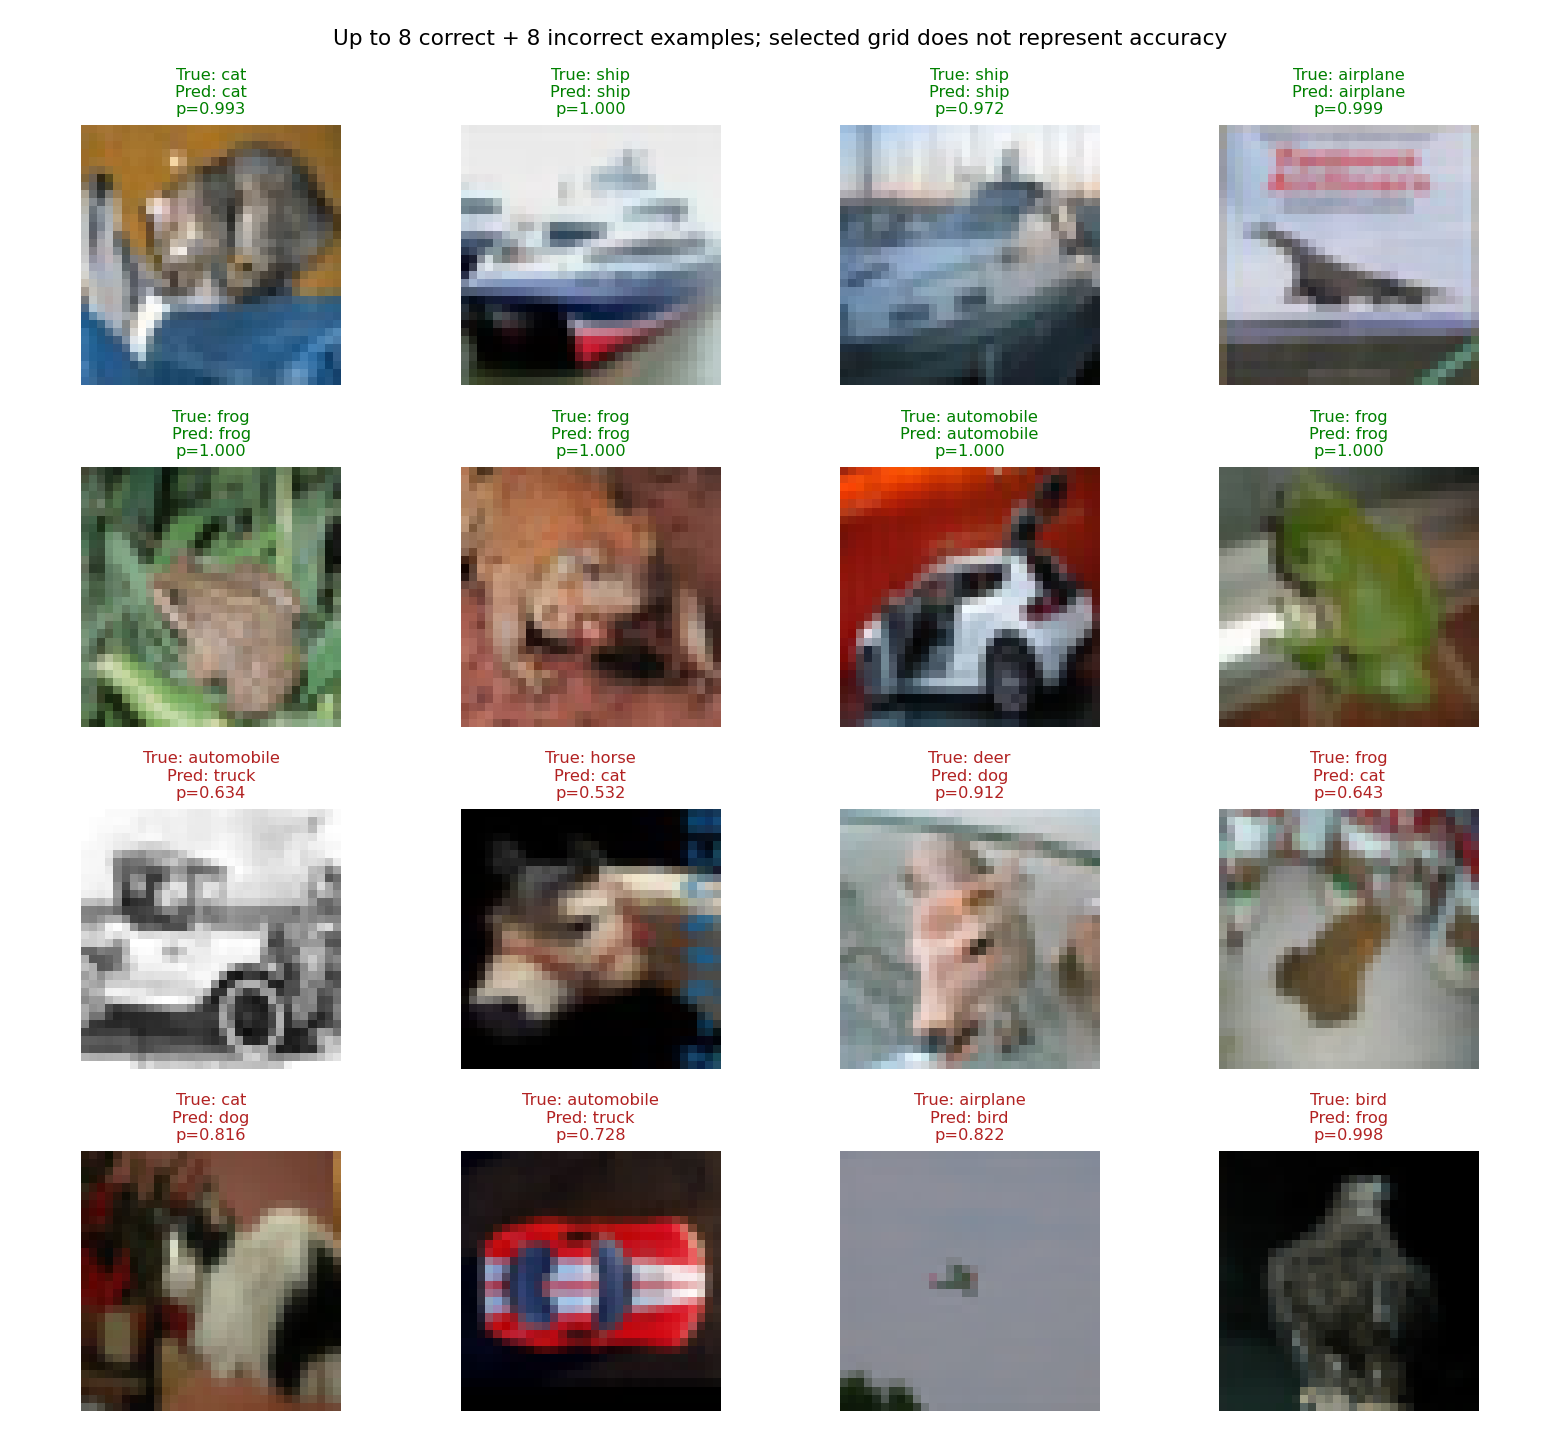

,Unnamed: 0,precision,recall,f1-score,support
0,airplane,0.921359,0.9490,0.934975,1000.0000
1,automobile,0.947473,0.9560,0.951717,1000.0000
2,bird,0.926804,0.8990,0.912690,1000.0000
3,cat,0.859756,0.8460,0.852823,1000.0000
4,deer,0.887297,0.9290,0.907670,1000.0000
5,dog,0.902490,0.8700,0.885947,1000.0000
6,frog,0.942744,0.9550,0.948833,1000.0000
7,horse,0.965373,0.9200,0.942140,1000.0000
8,ship,0.957086,0.9590,0.958042,1000.0000
9,truck,0.929961,0.9560,0.942801,1000.0000


,class,roc_auc,average_precision
0,airplane,0.997767,0.981794
1,automobile,0.998602,0.991313
2,bird,0.994844,0.969723
3,cat,0.990736,0.932851
4,deer,0.996050,0.972182
5,dog,0.992337,0.955551
6,frog,0.998255,0.987267
7,horse,0.998225,0.987522
8,ship,0.998374,0.990230
9,truck,0.998162,0.987122


Reload verification: {'passed': True, 'samples': 10000, 'max_probability_error': 0.0}


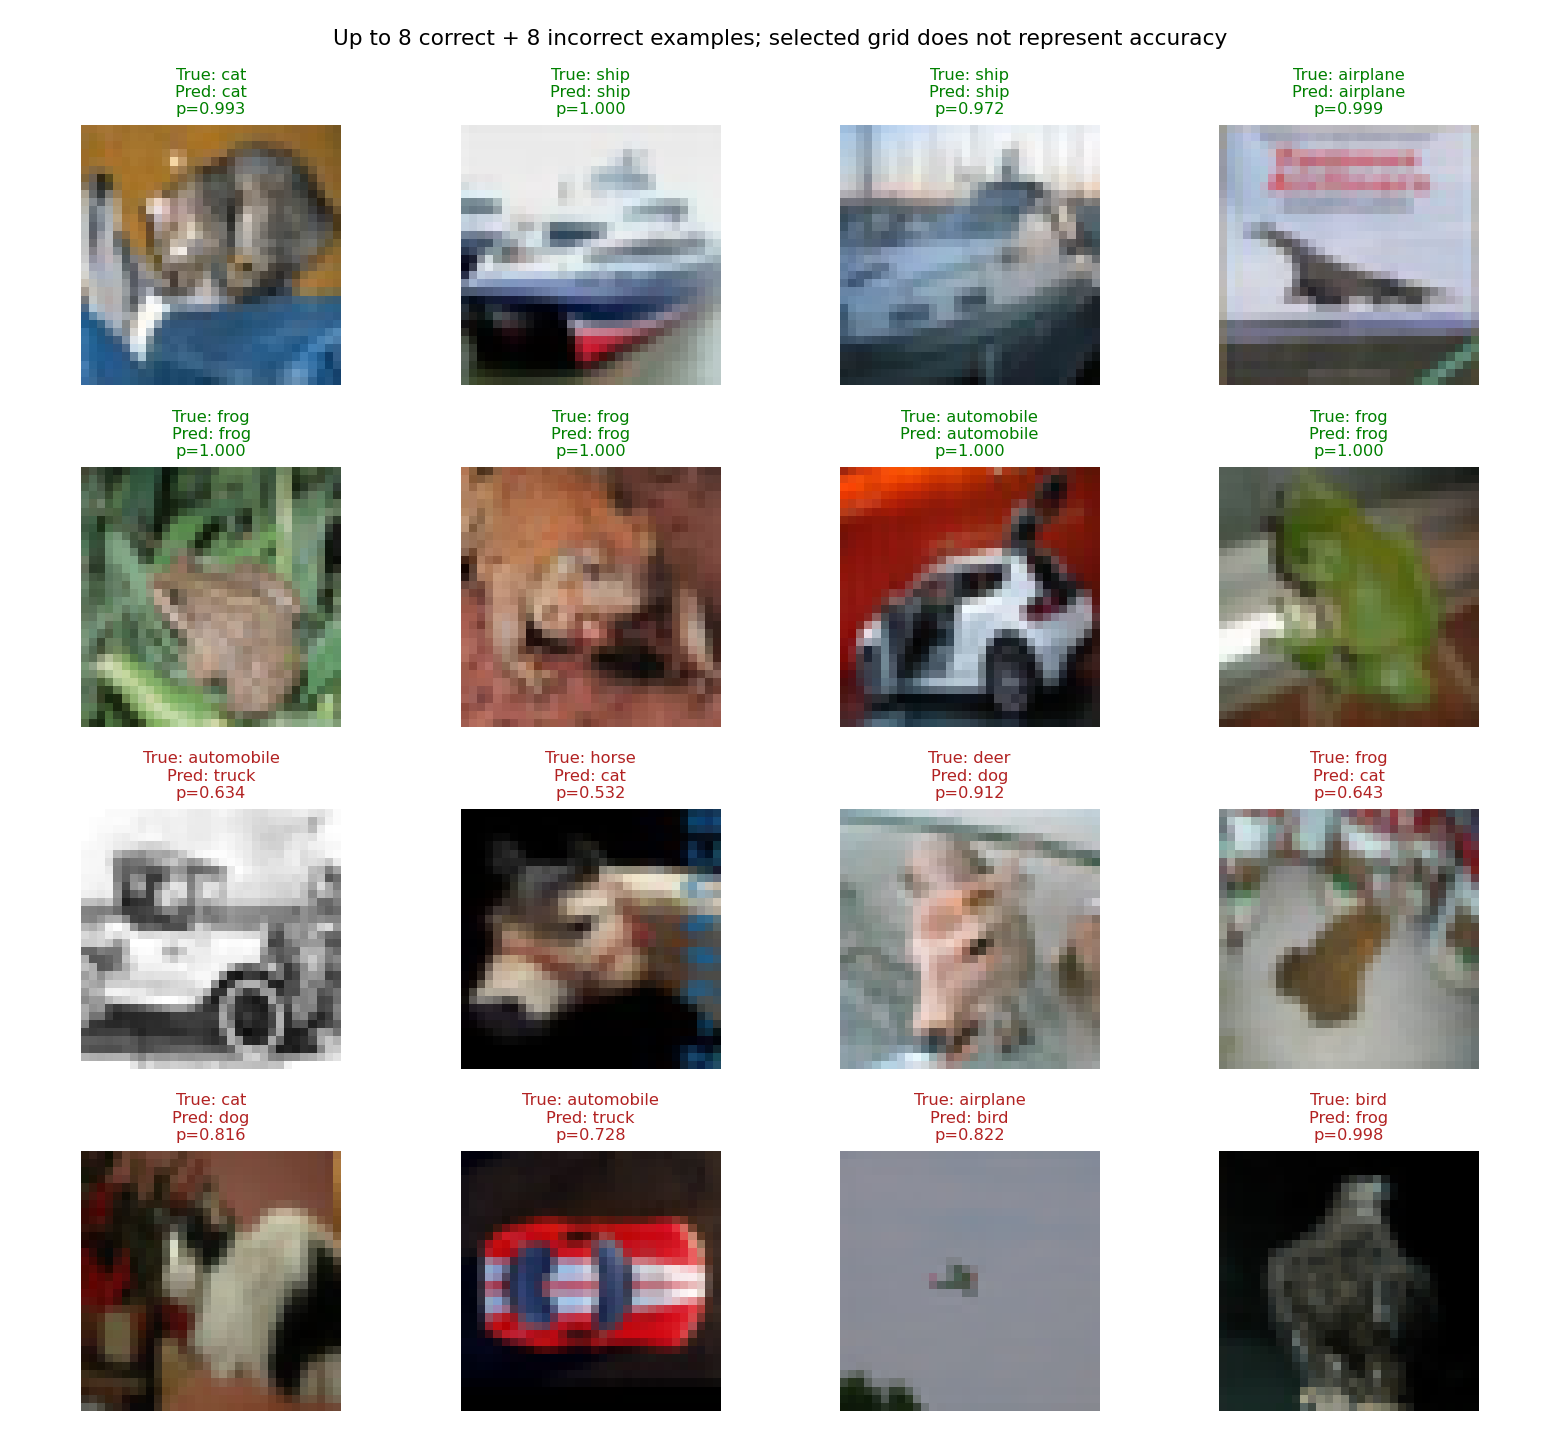

,index,true,predicted,probability
0,0,3,3,0.993274
1,1,8,8,0.999979
2,2,8,8,0.972257
3,3,0,0,0.998946
4,4,6,6,1.000000
5,5,6,6,0.999831
6,6,1,1,0.999809
7,7,6,6,1.000000
8,37,1,9,0.633803
9,57,7,3,0.532018


,model,stage,test_samples,accuracy,macro_f1,macro_precision,macro_recall,loss
0,resnet18,head,10000,0.8580,0.857751,0.858018,0.8580,0.402405
1,resnet18,finetune,10000,0.9108,0.910768,0.911151,0.9108,0.284503
2,densenet121,head,10000,0.8805,0.880326,0.880442,0.8805,0.344923
3,densenet121,finetune,10000,0.9239,0.923764,0.924034,0.9239,0.255533


In [13]:
results=[]
for name in cfg['models']:
    results.append(suite.evaluate(name))
    for stage in ('head','finetune'):
        folder=RUN/name/'evaluation'/stage
        print(name,stage)
        display(pd.Series(json.loads((folder/'metrics.json').read_text())).to_frame('test metrics'))
        for image_name in ('confusion_matrix.png','roc_pr.png','prediction_examples.png'):
            display(Image(filename=str(folder/image_name)))
        display(pd.read_csv(folder/'classification_report.csv'))
        display(pd.read_csv(folder/'roc_pr_metrics.csv'))
        print('Reload verification:',json.loads((folder/'roundtrip.json').read_text()))
        display(Image(filename=str(folder/'loaded/prediction_examples.png')))
        display(pd.read_csv(folder/'loaded/prediction_examples.csv'))
comparison=pd.concat(results,ignore_index=True)
comparison.to_csv(RUN/'comparison.csv',index=False)
display(comparison)


## 11. So sánh và bàn giao

So head/fine-tune cùng kiến trúc trước; fine-tune có thêm training nên không coi là ablation compute bằng nhau. Giữa hai model dùng cùng protocol nhưng số tham số/tốc độ khác nhau. Một seed và ba trial không đủ khẳng định tối ưu hoặc ưu thế thống kê. Đọc val loss tăng cùng train loss giảm để nhận diện overfit; không mặc định accuracy cao chứng minh không overfit. Không tuyên bố dưới 5 giờ nếu chưa đo.

Giữ original run/log/study/checkpoint local sau tải ZIP; chỉ publish evidence được chọn và đã rà riêng tư. Save Version và tải notebook đã chạy có output riêng bằng giao diện Kaggle.

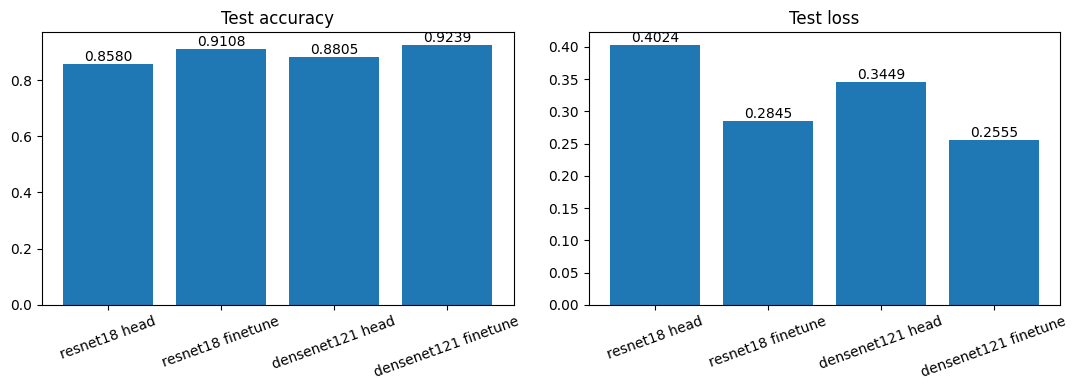

/kaggle/working/lab02_standard_outputs.zip

/kaggle/working/lab02_standard_outputs.zip


In [14]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
labels=comparison.model+' '+comparison.stage
for ax,key in zip(axes,('accuracy','loss')):
    bars=ax.bar(labels,comparison[key]);ax.bar_label(bars,fmt='%.4f');ax.set_title('Test '+key);ax.tick_params(axis='x',rotation=20)
fig.tight_layout();fig.savefig(RUN/'comparison.png',dpi=140);display(fig);plt.close(fig)
write_json(RUN/'status.json',{'status':'completed'})
suite.manifest()
package=shutil.make_archive('/kaggle/working/lab02_standard_outputs','zip',WORK,'outputs')
display(FileLink(package));print(package)
